<a href="https://colab.research.google.com/github/Rupesh756/Brain-tumor-Detection-using-deep-learning/blob/main/BrainTumor_3D_MONAI_All_Dataset_Training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 3D Brain Tumor Segmentation with MONAI UNet

Run the cells **in sequence from top to bottom**.

This notebook:
- Mounts Google Drive
- Downloads and extracts the MSD BrainTumour dataset
- Uses the complete dataset for both training and validation
- Builds MONAI transforms, datasets, and dataloaders
- Creates a 3D UNet
- Creates loss, Dice metric, optimizer, and scheduler
- Automatically resumes from the latest V3 checkpoint if available
- Saves latest checkpoint, best model, and training history

## Cell 1 — Install required packages

Run this cell first. After installation, if Colab asks for a runtime restart, restart the runtime and begin again from Cell 1.

In [2]:
!pip install -q monai nibabel tqdm
print("Required packages installed.")

Required packages installed.


## Cell 2 — Import libraries and mount Google Drive

In [3]:
import os
import glob
import json
import random
import tarfile
import time
import warnings

import torch
import torch.optim as optim

from google.colab import drive
from tqdm.auto import tqdm

from monai.transforms import (
    Compose,
    LoadImaged,
    EnsureChannelFirstd,
    NormalizeIntensityd,
    RandCropByPosNegLabeld,
    RandFlipd,
    EnsureTyped,
    AsDiscrete,
)

from monai.data import Dataset, DataLoader, decollate_batch
from monai.networks.nets import UNet
from monai.losses import DiceCELoss
from monai.metrics import DiceMetric
from monai.inferers import sliding_window_inference

drive.mount("/content/drive")

print("Imports completed and Google Drive mounted.")

Mounted at /content/drive
Imports completed and Google Drive mounted.


## Cell 3 — Configure project folders and device

In [4]:
PROJECT_DIR = "/content/drive/MyDrive/BrainTumorProject"

DATASET_ROOT = os.path.join(PROJECT_DIR, "dataset")
DATASET_DIR = os.path.join(DATASET_ROOT, "Task01_BrainTumour")

IMAGES_DIR = os.path.join(DATASET_DIR, "imagesTr")
LABELS_DIR = os.path.join(DATASET_DIR, "labelsTr")

CHECKPOINT_DIR = os.path.join(PROJECT_DIR, "checkpoints")
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")

os.makedirs(PROJECT_DIR, exist_ok=True)
os.makedirs(DATASET_ROOT, exist_ok=True)
os.makedirs(CHECKPOINT_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

LATEST_CHECKPOINT_PATH = os.path.join(
    CHECKPOINT_DIR, "latest_model_v3.pth"
)
BEST_MODEL_PATH = os.path.join(
    CHECKPOINT_DIR, "best_model_v3.pth"
)
HISTORY_PATH = os.path.join(
    CHECKPOINT_DIR, "training_history_v3.json"
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("=" * 65)
print("PROJECT CONFIGURATION")
print("=" * 65)
print("Project:", PROJECT_DIR)
print("Dataset:", DATASET_DIR)
print("Checkpoints:", CHECKPOINT_DIR)
print("Results:", RESULTS_DIR)
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU Memory:",
        round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
        "GB"
    )
else:
    warnings.warn("GPU is not available. 3D training may be very slow on CPU.")

print("PyTorch version:", torch.__version__)

PROJECT CONFIGURATION
Project: /content/drive/MyDrive/BrainTumorProject
Dataset: /content/drive/MyDrive/BrainTumorProject/dataset/Task01_BrainTumour
Checkpoints: /content/drive/MyDrive/BrainTumorProject/checkpoints
Results: /content/drive/MyDrive/BrainTumorProject/results
Device: cpu
PyTorch version: 2.14.1+cpu


/tmp/ipykernel_586/3464627738.py:46: UserWarning: GPU is not available. 3D training may be very slow on CPU.
  warnings.warn("GPU is not available. 3D training may be very slow on CPU.")


## Cell 4 — Download the dataset

The download is resumable. If the archive already exists, `wget -c` will continue or skip as appropriate.

In [ ]:
# SOURCE_FILE = "/content/Task01_BrainTumour.tar"

# if not os.path.exists(SOURCE_FILE):
#     print("Downloading dataset...")
#     !wget -c -O /content/Task01_BrainTumour.tar https://msd-for-monai.s3-us-west-2.amazonaws.com/Task01_BrainTumour.tar
# else:
#     print("Dataset archive already exists:", SOURCE_FILE)

# print("Archive ready:", os.path.getsize(SOURCE_FILE) / (1024**3), "GB")

--2026-11-19 12:26:14--  https://msd-for-monai.s3-us-west-2.amazonaws.com/Task01_BrainTumour.tar
Resolving msd-for-monai.s3-us-west-2.amazonaws.com (msd-for-monai.s3-us-west-2.amazonaws.com)... 3.5.87.69, 52.218.168.9, 52.92.234.106, ...
Connecting to msd-for-monai.s3-us-west-2.amazonaws.com (msd-for-monai.s3-us-west-2.amazonaws.com)|3.5.87.69|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 7608266240 (7.1G) [application/x-tar]
Saving to: ‘/content/Task01_BrainTumour.tar’

/content/Task01_Bra 100%[===================>]   7.08G  4.91MB/s    in 16m 54s 

2026-11-19 12:43:09 (7.16 MB/s) - ‘/content/Task01_BrainTumour.tar’ saved [7608266240/7608266240]

Archive ready: 7.085750102996826 GB


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Cell 5 — Extract the dataset

In [5]:
if not os.path.exists(DATASET_DIR):
    print("Extracting dataset...")
    with tarfile.open(SOURCE_FILE) as tar:
        tar.extractall(DATASET_ROOT)
    print("Dataset extraction completed.")
else:
    print("Dataset directory already exists. Extraction skipped.")

print("Dataset root contents:", os.listdir(DATASET_ROOT))
print("Dataset directory exists:", os.path.exists(DATASET_DIR))

Dataset directory already exists. Extraction skipped.
Dataset root contents: ['Task01_BrainTumour.tar', 'Task01_BrainTumour', 'data_split.json', 'data_split_v2.json']
Dataset directory exists: True


## Cell 6 — Locate image and label files

In [6]:
image_files = sorted(
    glob.glob(os.path.join(IMAGES_DIR, "*.nii.gz"))
)

label_files = sorted(
    glob.glob(os.path.join(LABELS_DIR, "*.nii.gz"))
)

print("Images found:", len(image_files))
print("Labels found:", len(label_files))

if len(image_files) == 0 or len(label_files) == 0:
    raise FileNotFoundError(
        "Images or labels were not found. Check the dataset extraction and paths."
    )

print("First image:", os.path.basename(image_files[0]))
print("First label:", os.path.basename(label_files[0]))

Images found: 484
Labels found: 484
First image: BRATS_001.nii.gz
First label: BRATS_001.nii.gz


In [ ]:
# # I will generate a Python code cell right after Cell 6 (9Dc0p7TFwk2y) that loops through all the image and label files, attempts to open each one with nibabel.load, and reports any corrupt files.
# import nibabel as nib
# from tqdm.auto import tqdm

# corrupted_files = []

# print("Checking all image and label files for corruption...")
# for filepath in tqdm(image_files + label_files):
#     try:
#         # Load the file headers and data to verify integrity
#         img = nib.load(filepath)
#         img.get_fdata()
#     except Exception as e:
#         print(f"\nCorrupted file detected: {filepath}")
#         print(f"Error: {e}")
#         corrupted_files.append(filepath)

# print("\n--- Verification Complete ---")
# if corrupted_files:
#     print(f"Found {len(corrupted_files)} corrupted file(s):")
#     for f in corrupted_files:
#         print(f)
# else:
#     print("All files read successfully! No corruption found.")

Checking all image and label files for corruption...


NameError: name 'image_files' is not defined

## Cell 7 — Use the complete dataset without splitting

In [7]:
RANDOM_SEED = 42
VAL_SPLIT = 0.20

all_patients = []

for image_path in image_files:
    filename = os.path.basename(image_path)
    label_path = os.path.join(LABELS_DIR, filename)

    if os.path.exists(label_path):
        all_patients.append({
            "image": image_path,
            "label": label_path
        })

if len(all_patients) < 2:
    raise RuntimeError("Not enough paired image-label files were found.")

random.seed(RANDOM_SEED)
random.shuffle(all_patients)

split_index = int(len(all_patients) * (1 - VAL_SPLIT))

train_files = all_patients[:split_index]
val_files = all_patients[split_index:]

print("=" * 65)
print("TRAIN / VALIDATION SPLIT")
print("=" * 65)
print("Total patients:", len(all_patients))
print("Training patients:", len(train_files))
print("Validation patients:", len(val_files))

assert len(all_patients) == len(train_files) + len(val_files)

print("Training example:", train_files[0])
print("Validation example:", val_files[0])
print("Patient split created successfully.")

TRAIN / VALIDATION SPLIT
Total patients: 484
Training patients: 387
Validation patients: 97
Training example: {'image': '/content/drive/MyDrive/BrainTumorProject/dataset/Task01_BrainTumour/imagesTr/BRATS_370.nii.gz', 'label': '/content/drive/MyDrive/BrainTumorProject/dataset/Task01_BrainTumour/labelsTr/BRATS_370.nii.gz'}
Validation example: {'image': '/content/drive/MyDrive/BrainTumorProject/dataset/Task01_BrainTumour/imagesTr/BRATS_332.nii.gz', 'label': '/content/drive/MyDrive/BrainTumorProject/dataset/Task01_BrainTumour/labelsTr/BRATS_332.nii.gz'}
Patient split created successfully.


## Cell 8 — Create MONAI transforms

In [8]:
ROI_SIZE = (96, 96, 96)

train_transforms = Compose([
    LoadImaged(keys=["image", "label"]),
    EnsureChannelFirstd(keys=["image", "label"]),

    NormalizeIntensityd(
        keys="image",
        nonzero=True,
        channel_wise=True
    ),

    RandFlipd(
        keys=["image", "label"],
        prob=0.5,
        spatial_axis=0
    ),
    RandFlipd(
        keys=["image", "label"],
        prob=0.5,
        spatial_axis=1
    ),
    RandFlipd(
        keys=["image", "label"],
        prob=0.5,
        spatial_axis=2
    ),

    RandCropByPosNegLabeld(
        keys=["image", "label"],
        label_key="label",
        spatial_size=ROI_SIZE,
        pos=1,
        neg=1,
        num_samples=1,
        image_key="image",
        image_threshold=0
    ),

    EnsureTyped(keys=["image", "label"])
])

val_transforms = Compose([
    LoadImaged(keys=["image", "label"]),
    EnsureChannelFirstd(keys=["image", "label"]),

    NormalizeIntensityd(
        keys="image",
        nonzero=True,
        channel_wise=True
    ),

    EnsureTyped(keys=["image", "label"])
])

print("Training and validation transforms created.")
print("ROI size:", ROI_SIZE)

Training and validation transforms created.
ROI size: (96, 96, 96)


## Cell 9 — Create datasets and dataloaders using the complete dataset

In [9]:
BATCH_SIZE = 1

train_dataset = Dataset(
    data=train_files,
    transform=train_transforms
)

val_dataset = Dataset(
    data=val_files,
    transform=val_transforms
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0
)

print("=" * 65)
print("DATASET AND DATALOADER INFORMATION")
print("=" * 65)
print("Training patients:", len(train_dataset))
print("Validation patients:", len(val_dataset))
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Batch size:", BATCH_SIZE)

DATASET AND DATALOADER INFORMATION
Training patients: 387
Validation patients: 97
Training batches: 387
Validation batches: 97
Batch size: 1


## Cell 10 — Test one training batch

This cell verifies the shape of the input image and segmentation label.

In [10]:
batch = next(iter(train_loader))

images = batch["image"]
labels = batch["label"]

print("Image shape:", tuple(images.shape))
print("Label shape:", tuple(labels.shape))
print("Image dtype:", images.dtype)
print("Label dtype:", labels.dtype)

assert images.shape[1] == 4, "Expected 4 MRI input channels."
print("Training batch test completed.")

Image shape: (1, 4, 96, 96, 96)
Label shape: (1, 1, 96, 96, 96)
Image dtype: torch.float32
Label dtype: torch.float32
Training batch test completed.


## Cell 11 — Create the 3D UNet model

In [11]:
model = UNet(
    spatial_dims=3,
    in_channels=4,
    out_channels=4,
    channels=(16, 32, 64, 128),
    strides=(2, 2, 2),
    num_res_units=2
).to(device)

print("3D UNet created on:", device)

3D UNet created on: cpu


## Cell 12 — Create loss function, metric, and postprocessing

In [12]:
loss_function = DiceCELoss(
    to_onehot_y=True,
    softmax=True,
    include_background=False
)

dice_metric = DiceMetric(
    include_background=False,
    reduction="mean"
)

post_pred = AsDiscrete(
    argmax=True,
    to_onehot=4
)

post_label = AsDiscrete(
    to_onehot=4
)

print("Loss function, Dice metric, and postprocessing created.")

Loss function, Dice metric, and postprocessing created.


## Cell 13 — Create optimizer and scheduler

In [13]:
optimizer = optim.Adam(
    model.parameters(),
    lr=1e-4
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=3,
    threshold=0.001,
    min_lr=1e-6
)

print("Optimizer and scheduler created.")
print("Initial learning rate:", optimizer.param_groups[0]["lr"])

Optimizer and scheduler created.
Initial learning rate: 0.0001


## Cell 14 — Initialize history and checkpoint helper

In [14]:
history = {
    "train_loss": [],
    "val_loss": [],
    "val_dice": []
}

best_dice = -1.0
start_epoch = 0

def save_checkpoint(epoch, best_dice_value):
    checkpoint = {
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "best_dice": float(best_dice_value),
        "history": history,
        "current_lr": float(optimizer.param_groups[0]["lr"])
    }

    torch.save(checkpoint, LATEST_CHECKPOINT_PATH)

    with open(HISTORY_PATH, "w") as f:
        json.dump(history, f, indent=2)

    print("Latest checkpoint saved:", LATEST_CHECKPOINT_PATH)
    print("History saved:", HISTORY_PATH)

print("Checkpoint helper created.")

Checkpoint helper created.


## Cell 15 — Automatically resume from the latest checkpoint if available

If no checkpoint exists, training starts from epoch 1. If a checkpoint exists, the model, optimizer, scheduler, history, and best Dice are restored.

In [15]:
if os.path.exists(LATEST_CHECKPOINT_PATH):
    print("Latest checkpoint found. Restoring training state...")

    checkpoint = torch.load(
        LATEST_CHECKPOINT_PATH,
        map_location=device,
        weights_only=False
    )

    model.load_state_dict(checkpoint["model_state_dict"])

    if "optimizer_state_dict" in checkpoint:
        optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

    if "scheduler_state_dict" in checkpoint:
        scheduler.load_state_dict(checkpoint["scheduler_state_dict"])

    start_epoch = int(checkpoint.get("epoch", -1)) + 1
    best_dice = float(checkpoint.get("best_dice", -1.0))

    if "history" in checkpoint:
        history = checkpoint["history"]
    elif os.path.exists(HISTORY_PATH):
        with open(HISTORY_PATH, "r") as f:
            history = json.load(f)

    print("Checkpoint restored successfully.")
    print("Last completed epoch:", start_epoch)
    print("Next epoch:", start_epoch + 1)
    print("Best Dice:", best_dice)
    print("Learning rate:", optimizer.param_groups[0]["lr"])

else:
    print("No checkpoint found. Starting fresh from epoch 1.")
    start_epoch = 0
    best_dice = -1.0

Latest checkpoint found. Restoring training state...
Checkpoint restored successfully.
Last completed epoch: 48
Next epoch: 49
Best Dice: 0.70013028383255
Learning rate: 1.25e-05


## Cell 16 — Final readiness check

In [16]:
NUM_EPOCHS = 50

required_objects = [
    model,
    train_loader,
    val_loader,
    optimizer,
    scheduler,
    loss_function,
    dice_metric
]

print("=" * 65)
print("FINAL TRAINING READINESS CHECK")
print("=" * 65)
print("Device:", device)
print("Total epochs:", NUM_EPOCHS)
print("Starting epoch:", start_epoch + 1)
print("Best Dice:", best_dice)
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Current learning rate:", optimizer.param_groups[0]["lr"])
print("All required training objects are ready.")

FINAL TRAINING READINESS CHECK
Device: cpu
Total epochs: 50
Starting epoch: 49
Best Dice: 0.70013028383255
Training batches: 387
Validation batches: 97
Current learning rate: 1.25e-05
All required training objects are ready.


## Cell 17 — Complete training function

Do not replace this function with `def train_model(...):`. Run this entire cell.

In [17]:
def train_model():
    global start_epoch
    global best_dice
    global history

    if start_epoch >= NUM_EPOCHS:
        print("Training is already complete for the selected NUM_EPOCHS.")
        print("Increase NUM_EPOCHS if you want to train further.")
        return

    print("=" * 65)
    print("STARTING TRAINING")
    print("=" * 65)
    print("Device:", device)
    print("Starting epoch:", start_epoch + 1)
    print("Total epochs:", NUM_EPOCHS)

    for epoch in range(start_epoch, NUM_EPOCHS):
        epoch_start_time = time.time()

        print("\n" + "=" * 65)
        print(f"EPOCH {epoch + 1}/{NUM_EPOCHS}")
        print(f"DEVICE: {device}")
        print(f"LEARNING RATE: {optimizer.param_groups[0]['lr']:.8f}")
        print("=" * 65)

        # -------------------------------
        # TRAINING
        # -------------------------------
        model.train()
        train_loss_total = 0.0

        train_progress = tqdm(
            train_loader,
            desc=f"Training Epoch {epoch + 1}"
        )

        for batch_data in train_progress:
            inputs = batch_data["image"].to(device)
            labels = batch_data["label"].to(device)

            optimizer.zero_grad(set_to_none=True)

            outputs = model(inputs)
            loss = loss_function(outputs, labels)

            loss.backward()
            optimizer.step()

            train_loss_total += loss.item()

            train_progress.set_postfix(
                loss=f"{loss.item():.4f}"
            )

        avg_train_loss = train_loss_total / max(len(train_loader), 1)

        # -------------------------------
        # VALIDATION
        # -------------------------------
        model.eval()
        val_loss_total = 0.0
        dice_metric.reset()

        val_progress = tqdm(
            val_loader,
            desc=f"Validation Epoch {epoch + 1}"
        )

        with torch.no_grad():
            for batch_idx, val_data in enumerate(val_progress):
                val_inputs = val_data["image"].to(device)
                val_labels = val_data["label"].to(device)

                val_outputs = sliding_window_inference(
                    inputs=val_inputs,
                    roi_size=ROI_SIZE,
                    sw_batch_size=1,
                    predictor=model,
                    overlap=0.25
                )

                val_loss = loss_function(
                    val_outputs,
                    val_labels
                )

                val_loss_total += val_loss.item()

                val_outputs_list = [
                    post_pred(item)
                    for item in decollate_batch(val_outputs)
                ]

                val_labels_list = [
                    post_label(item)
                    for item in decollate_batch(val_labels)
                ]

                dice_metric(
                    y_pred=val_outputs_list,
                    y=val_labels_list
                )

                running_val_loss = val_loss_total / (batch_idx + 1)

                if (batch_idx + 1) % 5 == 0:
                    running_dice = dice_metric.aggregate().item()
                    val_progress.set_postfix(
                        val_loss=f"{running_val_loss:.4f}",
                        dice=f"{running_dice:.4f}"
                    )
                else:
                    val_progress.set_postfix(
                        val_loss=f"{running_val_loss:.4f}"
                    )

        avg_val_loss = val_loss_total / max(len(val_loader), 1)
        val_dice = dice_metric.aggregate().item()
        dice_metric.reset()

        # -------------------------------
        # SCHEDULER
        # -------------------------------
        scheduler.step(val_dice)

        # -------------------------------
        # HISTORY
        # -------------------------------
        history["train_loss"].append(float(avg_train_loss))
        history["val_loss"].append(float(avg_val_loss))
        history["val_dice"].append(float(val_dice))

        # -------------------------------
        # BEST MODEL
        # -------------------------------
        is_new_best = val_dice > best_dice

        if is_new_best:
            best_dice = float(val_dice)

            best_checkpoint = {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "scheduler_state_dict": scheduler.state_dict(),
                "best_dice": best_dice,
                "history": history,
                "current_lr": float(optimizer.param_groups[0]["lr"])
            }

            torch.save(best_checkpoint, BEST_MODEL_PATH)
            print("\nNEW BEST MODEL SAVED:", BEST_MODEL_PATH)

        # -------------------------------
        # LATEST CHECKPOINT
        # -------------------------------
        save_checkpoint(epoch, best_dice)

        start_epoch = epoch + 1

        epoch_time_minutes = (time.time() - epoch_start_time) / 60

        print("\nEPOCH RESULTS")
        print("-" * 45)
        print(f"Epoch: {epoch + 1}/{NUM_EPOCHS}")
        print(f"Train Loss: {avg_train_loss:.4f}")
        print(f"Validation Loss: {avg_val_loss:.4f}")
        print(f"Validation Dice: {val_dice:.4f}")
        print(f"Best Dice: {best_dice:.4f}")
        print(f"Learning Rate: {optimizer.param_groups[0]['lr']:.8f}")
        print(f"Time: {epoch_time_minutes:.2f} minutes")

    print("\n" + "=" * 65)
    print("TRAINING COMPLETED")
    print("=" * 65)
    print("Total epochs:", NUM_EPOCHS)
    print("Best validation Dice:", best_dice)

## Cell 18 — Start or continue training

Run this cell only after all previous cells have completed successfully.

In [1]:
train_model()

NameError: name 'train_model' is not defined

## Cell 19 — Check saved files

In [18]:
from monai.transforms import LoadImage

loader = LoadImage(image_only=True)

try:
    image = loader(file_path)
    print("MONAI loading successful")
    print("Image shape:", image.shape)
except Exception as e:
    print("MONAI loading failed:")
    print(repr(e))

MONAI loading failed:
NameError("name 'file_path' is not defined")


In [ ]:
# import os
# import shutil

# DRIVE_DATASET = (
#     "/content/drive/MyDrive/BrainTumorProject/dataset"
# )

# LOCAL_DATASET = "/content/brain_dataset"

# if not os.path.exists(LOCAL_DATASET):
#     shutil.copytree(DRIVE_DATASET, LOCAL_DATASET)

# print("Dataset copied successfully")
# print("Local dataset:", LOCAL_DATASET)

Dataset copied successfully
Local dataset: /content/brain_dataset


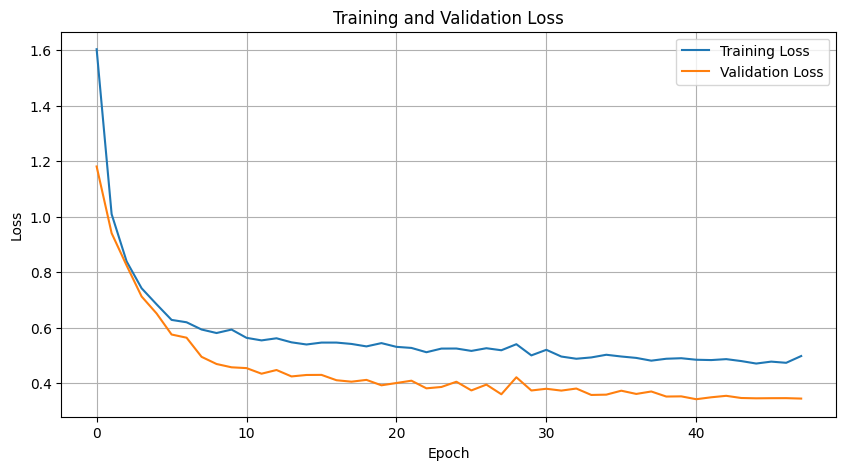

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(history["train_loss"], label="Training Loss")
plt.plot(history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

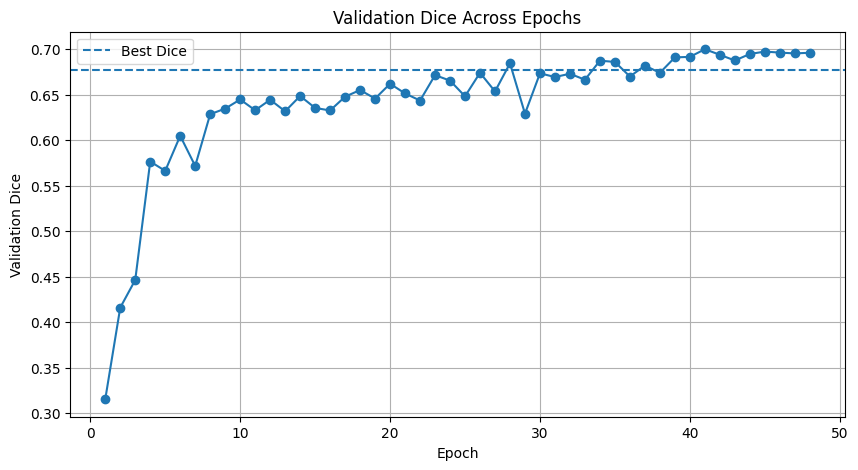

In [20]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(history["val_dice"]) + 1),
    history["val_dice"],
    marker="o"
)

plt.axhline(0.6769, linestyle="--", label="Best Dice")

plt.xlabel("Epoch")
plt.ylabel("Validation Dice")
plt.title("Validation Dice Across Epochs")
plt.legend()
plt.grid(True)
plt.show()

In [23]:
import torch
import os

path = "/content/drive/MyDrive/BrainTumorProject/checkpoints/best_model_v3.pth"

checkpoint = torch.load(
    path,
    map_location="cpu",
    weights_only=False
)

print("Checkpoint exists:", os.path.exists(path))
print("Checkpoint keys:", checkpoint.keys())

if "epoch" in checkpoint:
    print("Best checkpoint epoch:", checkpoint["epoch"])

if "best_dice" in checkpoint:
    print("Best Dice:", checkpoint["best_dice"])

Checkpoint exists: True
Checkpoint keys: dict_keys(['epoch', 'model_state_dict', 'optimizer_state_dict', 'scheduler_state_dict', 'best_dice', 'history', 'current_lr'])
Best checkpoint epoch: 40
Best Dice: 0.70013028383255


In [24]:
import os

DATA_DIR = "/content/drive/MyDrive/BrainTumorProject"

for root, dirs, files in os.walk(DATA_DIR):
    dirs[:] = [d for d in dirs if d not in ["checkpoints"]]
    if files:
        print(f"\nFolder: {root}")
        print("Number of files:", len(files))
        print("Examples:", files[:5])


Folder: /content/drive/MyDrive/BrainTumorProject/dataset
Number of files: 3
Examples: ['Task01_BrainTumour.tar', 'data_split.json', 'data_split_v2.json']

Folder: /content/drive/MyDrive/BrainTumorProject/dataset/Task01_BrainTumour
Number of files: 5
Examples: ['._imagesTr', '._imagesTs', '._labelsTr', '._dataset.json', 'dataset.json']

Folder: /content/drive/MyDrive/BrainTumorProject/dataset/Task01_BrainTumour/imagesTr
Number of files: 495
Examples: ['BRATS_001.nii.gz', '._BRATS_001.nii.gz', '._BRATS_002.nii.gz', 'BRATS_002.nii.gz', 'BRATS_003.nii.gz']

Folder: /content/drive/MyDrive/BrainTumorProject/dataset/Task01_BrainTumour/imagesTs
Number of files: 289
Examples: ['BRATS_485.nii.gz', 'BRATS_486.nii.gz', 'BRATS_487.nii.gz', '._BRATS_487.nii.gz', '._BRATS_488.nii.gz']

Folder: /content/drive/MyDrive/BrainTumorProject/dataset/Task01_BrainTumour/labelsTr
Number of files: 485
Examples: ['BRATS_001.nii.gz', 'BRATS_003.nii.gz', 'BRATS_002.nii.gz', 'BRATS_004.nii.gz', 'BRATS_005.nii.gz']


In [25]:
import os
import json
import glob
import nibabel as nib
import numpy as np

BASE = "/content/drive/MyDrive/BrainTumorProject"

DATA_DIR = os.path.join(
    BASE, "dataset/Task01_BrainTumour"
)

SPLIT_DIR = os.path.join(BASE, "version3/split")

# Load split files
with open(os.path.join(SPLIT_DIR, "train_files.json")) as f:
    train_files = json.load(f)

with open(os.path.join(SPLIT_DIR, "val_files.json")) as f:
    val_files = json.load(f)

print("TRAIN FILE EXAMPLE:")
print(train_files[:2])

print("\nVALIDATION FILE EXAMPLE:")
print(val_files[:2])

# Extract filenames regardless of JSON structure
def get_names(items):
    names = []
    for item in items:
        if isinstance(item, str):
            name = item
        elif isinstance(item, dict):
            name = item.get("image", item.get("label", ""))
        else:
            continue

        if name:
            names.append(os.path.basename(name))

    return set(names)

train_names = get_names(train_files)
val_names = get_names(val_files)

print("\nSPLIT SUMMARY")
print("Training cases:", len(train_names))
print("Validation cases:", len(val_names))
print("Overlap:", len(train_names & val_names))

# Count only actual NIfTI files, excluding AppleDouble files
images = {
    os.path.basename(p)
    for p in glob.glob(os.path.join(DATA_DIR, "imagesTr", "BRATS_*.nii.gz"))
    if not os.path.basename(p).startswith("._")
}

labels = {
    os.path.basename(p)
    for p in glob.glob(os.path.join(DATA_DIR, "labelsTr", "BRATS_*.nii.gz"))
    if not os.path.basename(p).startswith("._")
}

print("\nDATASET SUMMARY")
print("Training images:", len(images))
print("Training labels:", len(labels))
print("Matched image-label pairs:", len(images & labels))
print("Images without labels:", len(images - labels))
print("Labels without images:", len(labels - images))

# Check whether all labelled cases were used
used = train_names | val_names

print("\nSPLIT COVERAGE")
print("Cases in train + validation:", len(used))
print("Cases not included in split:", len(images & labels - used))

# Inspect dataset metadata
with open(os.path.join(DATA_DIR, "dataset.json")) as f:
    metadata = json.load(f)

print("\nDATASET LABEL INFORMATION")
print(json.dumps(metadata.get("labels", {}), indent=2))

TRAIN FILE EXAMPLE:
[{'image': '/content/drive/MyDrive/BrainTumorProject/dataset/Task01_BrainTumour/imagesTr/BRATS_413.nii.gz', 'label': '/content/drive/MyDrive/BrainTumorProject/dataset/Task01_BrainTumour/labelsTr/BRATS_413.nii.gz'}, {'image': '/content/drive/MyDrive/BrainTumorProject/dataset/Task01_BrainTumour/imagesTr/BRATS_026.nii.gz', 'label': '/content/drive/MyDrive/BrainTumorProject/dataset/Task01_BrainTumour/labelsTr/BRATS_026.nii.gz'}]

VALIDATION FILE EXAMPLE:
[{'image': '/content/drive/MyDrive/BrainTumorProject/dataset/Task01_BrainTumour/imagesTr/BRATS_419.nii.gz', 'label': '/content/drive/MyDrive/BrainTumorProject/dataset/Task01_BrainTumour/labelsTr/BRATS_419.nii.gz'}, {'image': '/content/drive/MyDrive/BrainTumorProject/dataset/Task01_BrainTumour/imagesTr/BRATS_475.nii.gz', 'label': '/content/drive/MyDrive/BrainTumorProject/dataset/Task01_BrainTumour/labelsTr/BRATS_475.nii.gz'}]

SPLIT SUMMARY
Training cases: 387
Validation cases: 97
Overlap: 0

DATASET SUMMARY
Training ima

In [26]:
import json

dataset_json = (
    "/content/drive/MyDrive/BrainTumorProject/"
    "dataset/Task01_BrainTumour/dataset.json"
)

with open(dataset_json, "r") as f:
    metadata = json.load(f)

print("MRI MODALITIES:")
print(json.dumps(metadata.get("modality", {}), indent=4))

print("\nSEGMENTATION LABELS:")
print(json.dumps(metadata.get("labels", {}), indent=4))

MRI MODALITIES:
{
    "0": "FLAIR",
    "1": "T1w",
    "2": "t1gd",
    "3": "T2w"
}

SEGMENTATION LABELS:
{
    "0": "background",
    "1": "edema",
    "2": "non-enhancing tumor",
    "3": "enhancing tumour"
}


**Create the destination folder in Google Drive for external dataset**

In [27]:
from google.colab import drive
import os

drive.mount('/content/drive')

DOWNLOAD_DIR = (
    "/content/drive/MyDrive/BrainTumorProject/"
    "external_dataset/UTSW_Glioma"
)

os.makedirs(DOWNLOAD_DIR, exist_ok=True)

print("Dataset destination:", DOWNLOAD_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset destination: /content/drive/MyDrive/BrainTumorProject/external_dataset/UTSW_Glioma


In [28]:
!pip install -q huggingface_hub nibabel

import os
import json
import requests
import nibabel as nib
import numpy as np

from huggingface_hub import HfApi, hf_hub_download

# Dataset repository
REPO_ID = "MedOtter/brats2023-gli-dataset"

# Save location in Google Drive
from google.colab import drive
drive.mount('/content/drive')

SAVE_DIR = "/content/drive/MyDrive/BrainTumorProject/external_dataset/BraTS2023"
os.makedirs(SAVE_DIR, exist_ok=True)

# Download only the small metadata file
metadata_url = (
    "https://huggingface.co/datasets/"
    + REPO_ID + "/resolve/main/train.jsonl"
)

response = requests.get(metadata_url)
response.raise_for_status()

records = [
    json.loads(line)
    for line in response.text.splitlines()
    if line.strip()
]

print("Available patient records:", len(records))

# Select one patient
patient = records[0]

print("Patient ID:", patient["patient_id"])

# Get repository file listing
api = HfApi()
repo_files = api.list_repo_files(
    repo_id=REPO_ID,
    repo_type="dataset"
)

# Download one patient’s four modalities and mask
files_to_download = {
    "t1n": patient["modalities"]["t1n"],
    "t1c": patient["modalities"]["t1c"],
    "t2w": patient["modalities"]["t2w"],
    "t2f": patient["modalities"]["t2f"],
    "seg": patient["mask"]
}

downloaded = {}

for modality, metadata_path in files_to_download.items():

    filename = os.path.basename(metadata_path)

    # Match the actual file in the repository
    matches = [
        f for f in repo_files
        if f.endswith("/" + filename) or f == filename
    ]

    if not matches:
        raise FileNotFoundError(
            f"Could not find {filename} in the repository"
        )

    actual_path = matches[0]

    local_path = hf_hub_download(
        repo_id=REPO_ID,
        filename=actual_path,
        repo_type="dataset",
        local_dir=SAVE_DIR
    )

    downloaded[modality] = local_path
    print(f"Downloaded {modality}: {local_path}")

print("\nDownload completed.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Available patient records: 1251
Patient ID: BraTS-GLI-00000-000


ASNR-MICCAI-BraTS2023-GLI-Challenge-Trai(…): reconstructing file:   0%|          |  0.00B / 2.33MB            

ASNR-MICCAI-BraTS2023-GLI-Challenge-Trai(…): downloading bytes:           |  0.00B            

Downloaded t1n: /content/drive/MyDrive/BrainTumorProject/external_dataset/BraTS2023/ASNR-MICCAI-BraTS2023-GLI-Challenge-TrainingData/BraTS-GLI-00000-000/BraTS-GLI-00000-000-t1n.nii.gz


ASNR-MICCAI-BraTS2023-GLI-Challenge-Trai(…): reconstructing file:   0%|          |  0.00B / 2.64MB            

ASNR-MICCAI-BraTS2023-GLI-Challenge-Trai(…): downloading bytes:           |  0.00B            

... (6 outputs left out)

Downloaded t2f: /content/drive/MyDrive/BrainTumorProject/external_dataset/BraTS2023/ASNR-MICCAI-BraTS2023-GLI-Challenge-TrainingData/BraTS-GLI-00000-000/BraTS-GLI-00000-000-t2f.nii.gz


ASNR-MICCAI-BraTS2023-GLI-Challenge-Trai(…): reconstructing file:   0%|          |  0.00B / 49.9kB            

ASNR-MICCAI-BraTS2023-GLI-Challenge-Trai(…): downloading bytes:           |  0.00B            

Downloaded seg: /content/drive/MyDrive/BrainTumorProject/external_dataset/BraTS2023/ASNR-MICCAI-BraTS2023-GLI-Challenge-TrainingData/BraTS-GLI-00000-000/BraTS-GLI-00000-000-seg.nii.gz

Download completed.


In [29]:
# Load modalities in the exact order expected by your model
flair = nib.load(downloaded["t2f"]).get_fdata()
t1 = nib.load(downloaded["t1n"]).get_fdata()
t1gd = nib.load(downloaded["t1c"]).get_fdata()
t2 = nib.load(downloaded["t2w"]).get_fdata()

# Load segmentation mask
mask = nib.load(downloaded["seg"]).get_fdata()

# Stack channels: FLAIR, T1, T1gd, T2
image = np.stack(
    [flair, t1, t1gd, t2],
    axis=-1
)

print("Image shape:", image.shape)
print("Mask shape:", mask.shape)

print("Mask labels:", np.unique(mask))
print("Image min:", np.min(image))
print("Image max:", np.max(image))

Image shape: (240, 240, 155, 4)
Mask shape: (240, 240, 155)
Mask labels: [0. 1. 2. 3.]
Image min: 0.0
Image max: 12343.0


In [30]:
# Convert BraTS labels to your model's label convention
converted_mask = np.zeros(mask.shape, dtype=np.uint8)

converted_mask[mask == 1] = 2
converted_mask[mask == 2] = 1
converted_mask[mask == 3] = 3

print("Converted labels:", np.unique(converted_mask))

Converted labels: [0 1 2 3]


In [31]:
# 2. Next: Check image geometry and modality alignment
import nibabel as nib
import numpy as np

modalities = ["t2f", "t1n", "t1c", "t2w"]

reference = nib.load(downloaded["t2f"])

print("Reference shape:", reference.shape)
print("Reference affine:")
print(reference.affine)

for modality in modalities:
    nii = nib.load(downloaded[modality])

    print(f"\n{modality}")
    print("Shape:", nii.shape)
    print("Affine matches:", np.allclose(
        reference.affine, nii.affine, atol=1e-4
    ))

seg_nii = nib.load(downloaded["seg"])

print("\nSegmentation shape:", seg_nii.shape)
print("Segmentation affine matches:",
      np.allclose(reference.affine, seg_nii.affine, atol=1e-4))

Reference shape: (240, 240, 155)
Reference affine:
[[ -1.  -0.  -0.   0.]
 [ -0.  -1.  -0. 239.]
 [  0.   0.   1.   0.]
 [  0.   0.   0.   1.]]

t2f
Shape: (240, 240, 155)
Affine matches: True

t1n
Shape: (240, 240, 155)
Affine matches: True

t1c
Shape: (240, 240, 155)
Affine matches: True

t2w
Shape: (240, 240, 155)
Affine matches: True

Segmentation shape: (240, 240, 155)
Segmentation affine matches: True


In [32]:
labels, counts = np.unique(
    converted_mask, return_counts=True
)

label_names = {
    0: "Background",
    1: "Edema",
    2: "Non-enhancing tumour",
    3: "Enhancing tumour"
}

for label, count in zip(labels, counts):
    print(
        f"{label_names[int(label)]}: "
        f"{count:,} voxels"
    )

Background: 8,870,695 voxels
Edema: 12,836 voxels
Non-enhancing tumour: 11,738 voxels
Enhancing tumour: 32,731 voxels


In [33]:
import nibabel as nib
import numpy as np
import glob
import os

# External BraTS case
external = nib.load(downloaded["t2f"])

# One original MSD training image
msd_files = glob.glob(
    "/content/drive/MyDrive/BrainTumorProject/dataset/"
    "Task01_BrainTumour/imagesTr/BRATS_*.nii.gz"
)

msd_file = msd_files[0]
msd = nib.load(msd_file)

def show_geometry(name, nii):
    print(f"\n{name}")
    print("Shape:", nii.shape)
    print("Voxel spacing:", nii.header.get_zooms()[:3])
    print("Orientation:", nib.aff2axcodes(nii.affine))
    print("Affine:")
    print(nii.affine)

show_geometry("External BraTS", external)
show_geometry("Original MSD", msd)


External BraTS
Shape: (240, 240, 155)
Voxel spacing: (np.float32(1.0), np.float32(1.0), np.float32(1.0))
Orientation: ('L', 'P', 'S')
Affine:
[[ -1.  -0.  -0.   0.]
 [ -0.  -1.  -0. 239.]
 [  0.   0.   1.   0.]
 [  0.   0.   0.   1.]]

Original MSD
Shape: (240, 240, 155, 4)
Voxel spacing: (np.float32(1.0), np.float32(1.0), np.float32(1.0))
Orientation: ('R', 'A', 'S')
Affine:
[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]


In [34]:
modalities = ["t2f", "t1n", "t1c", "t2w"]

for modality in modalities:
    nii = nib.load(downloaded[modality])
    arr = nii.get_fdata().astype(np.float32)

    nonzero = arr[arr > 0]

    print(f"\n{modality}")
    print("Min:", np.min(arr))
    print("Max:", np.max(arr))
    print("Mean (nonzero):", np.mean(nonzero))
    print("Std (nonzero):", np.std(nonzero))
    print("Percentiles:", np.percentile(nonzero, [1, 25, 50, 75, 99]))


t2f
Min: 0.0
Max: 2934.0
Mean (nonzero): 987.1395
Std (nonzero): 357.7222
Percentiles: [ 104.  794.  997. 1227. 1778.]

t1n
Min: 0.0
Max: 2023.0
Mean (nonzero): 802.2093
Std (nonzero): 171.70546
Percentiles: [ 301.  711.  827.  922. 1125.]

t1c
Min: 0.0
Max: 12343.0
Mean (nonzero): 2084.0015
Std (nonzero): 837.8845
Percentiles: [ 673. 1649. 1993. 2355. 5574.]

t2w
Min: 0.0
Max: 2421.0
Mean (nonzero): 565.6712
Std (nonzero): 312.47632
Percentiles: [  59.  408.  486.  602. 1930.]


In [35]:
# Step 1: Convert external data to RAS
import nibabel as nib
import numpy as np
import os

ras_dir = (
    "/content/drive/MyDrive/BrainTumorProject/"
    "external_dataset/BraTS2023/RAS"
)

os.makedirs(ras_dir, exist_ok=True)

modalities = ["t2f", "t1n", "t1c", "t2w", "seg"]

ras_files = {}

for modality in modalities:
    nii = nib.load(downloaded[modality])

    # Convert to RAS orientation
    ras_nii = nib.as_closest_canonical(nii)

    output_path = os.path.join(
        ras_dir, f"BraTS2023_{modality}_RAS.nii.gz"
    )

    nib.save(ras_nii, output_path)
    ras_files[modality] = output_path

    print(f"\n{modality}")
    print("Original orientation:", nib.aff2axcodes(nii.affine))
    print("New orientation:", nib.aff2axcodes(ras_nii.affine))
    print("New shape:", ras_nii.shape)


t2f
Original orientation: ('L', 'P', 'S')
New orientation: ('R', 'A', 'S')
New shape: (240, 240, 155)

t1n
Original orientation: ('L', 'P', 'S')
New orientation: ('R', 'A', 'S')
New shape: (240, 240, 155)

t1c
Original orientation: ('L', 'P', 'S')
New orientation: ('R', 'A', 'S')
New shape: (240, 240, 155)

t2w
Original orientation: ('L', 'P', 'S')
New orientation: ('R', 'A', 'S')
New shape: (240, 240, 155)

seg
Original orientation: ('L', 'P', 'S')
New orientation: ('R', 'A', 'S')
New shape: (240, 240, 155)


In [37]:
# Step 3: Important preprocessing details
NormalizeIntensityd(
    keys="image",
    nonzero=True,
    channel_wise=True
)

In [38]:
# [FLAIR, T1, T1ce, T2]
image = np.stack([
    nib.load(ras_files["t2f"]).get_fdata(),
    nib.load(ras_files["t1n"]).get_fdata(),
    nib.load(ras_files["t1c"]).get_fdata(),
    nib.load(ras_files["t2w"]).get_fdata()
], axis=0).astype(np.float32)

mask = nib.load(ras_files["seg"]).get_fdata().astype(np.uint8)

print("Image shape:", image.shape)
print("Mask shape:", mask.shape)

Image shape: (4, 240, 240, 155)
Mask shape: (240, 240, 155)


In [39]:
# Step 4: Load the existing model and run inference
#  It uses your existing model architecture and best_model_v3.pth checkpoint.
# 4.1 Load and normalize the external MRI
# The normalization below uses the nonzero mean and standard deviation separately for each channel, matching your training configuration.
import torch
import numpy as np
import nibabel as nib
import os

from monai.inferers import sliding_window_inference
from monai.networks.nets import UNet

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# Load RAS-converted modalities in the original training order
image_np = np.stack([
    nib.load(ras_files["t2f"]).get_fdata(),
    nib.load(ras_files["t1n"]).get_fdata(),
    nib.load(ras_files["t1c"]).get_fdata(),
    nib.load(ras_files["t2w"]).get_fdata()
], axis=0).astype(np.float32)

# Channel-wise nonzero normalization
image = torch.from_numpy(image_np)

for c in range(4):
    channel = image[c]
    nonzero_mask = channel != 0

    values = channel[nonzero_mask]

    mean = values.mean()
    std = values.std()

    if std > 0:
        channel[nonzero_mask] = (values - mean) / std

    image[c] = channel

# Add batch dimension: [1, 4, 240, 240, 155]
input_tensor = image.unsqueeze(0).to(device)

print("Input tensor shape:", input_tensor.shape)
print("Input tensor device:", input_tensor.device)

Device: cpu
Input tensor shape: torch.Size([1, 4, 240, 240, 155])
Input tensor device: cpu


In [40]:
# 4.2 Recreate the trained 3D U-Net
model = UNet(
    spatial_dims=3,
    in_channels=4,
    out_channels=4,
    channels=(16, 32, 64, 128),
    strides=(2, 2, 2),
    num_res_units=2
).to(device)

In [41]:
# loading best checkpoint
checkpoint_path = (
    "/content/drive/MyDrive/BrainTumorProject/"
    "checkpoints/best_model_v3.pth"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

# Support common checkpoint formats
if isinstance(checkpoint, dict):
    if "model_state_dict" in checkpoint:
        state_dict = checkpoint["model_state_dict"]
    elif "state_dict" in checkpoint:
        state_dict = checkpoint["state_dict"]
    elif "model" in checkpoint:
        state_dict = checkpoint["model"]
    else:
        state_dict = checkpoint
else:
    state_dict = checkpoint

# Handle checkpoints saved using DataParallel
state_dict = {
    key.replace("module.", "", 1): value
    for key, value in state_dict.items()
}

model.load_state_dict(state_dict, strict=True)
model.eval()

print("Best checkpoint loaded successfully.")

RuntimeError: Error(s) in loading state_dict for UNet:
	Missing key(s) in state_dict: "model.1.submodule.0.conv.unit0.conv.weight", "model.1.submodule.0.conv.unit0.conv.bias", "model.1.submodule.0.conv.unit0.adn.A.weight", "model.1.submodule.0.conv.unit1.conv.weight", "model.1.submodule.0.conv.unit1.conv.bias", "model.1.submodule.0.conv.unit1.adn.A.weight", "model.1.submodule.0.residual.weight", "model.1.submodule.0.residual.bias", "model.1.submodule.1.submodule.0.conv.unit0.conv.weight", "model.1.submodule.1.submodule.0.conv.unit0.conv.bias", "model.1.submodule.1.submodule.0.conv.unit0.adn.A.weight", "model.1.submodule.1.submodule.0.conv.unit1.conv.weight", "model.1.submodule.1.submodule.0.conv.unit1.conv.bias", "model.1.submodule.1.submodule.0.conv.unit1.adn.A.weight", "model.1.submodule.1.submodule.0.residual.weight", "model.1.submodule.1.submodule.0.residual.bias", "model.1.submodule.1.submodule.1.submodule.conv.unit0.conv.weight", "model.1.submodule.1.submodule.1.submodule.conv.un

Ground-truth tumour centroid: (139, 83, 71)


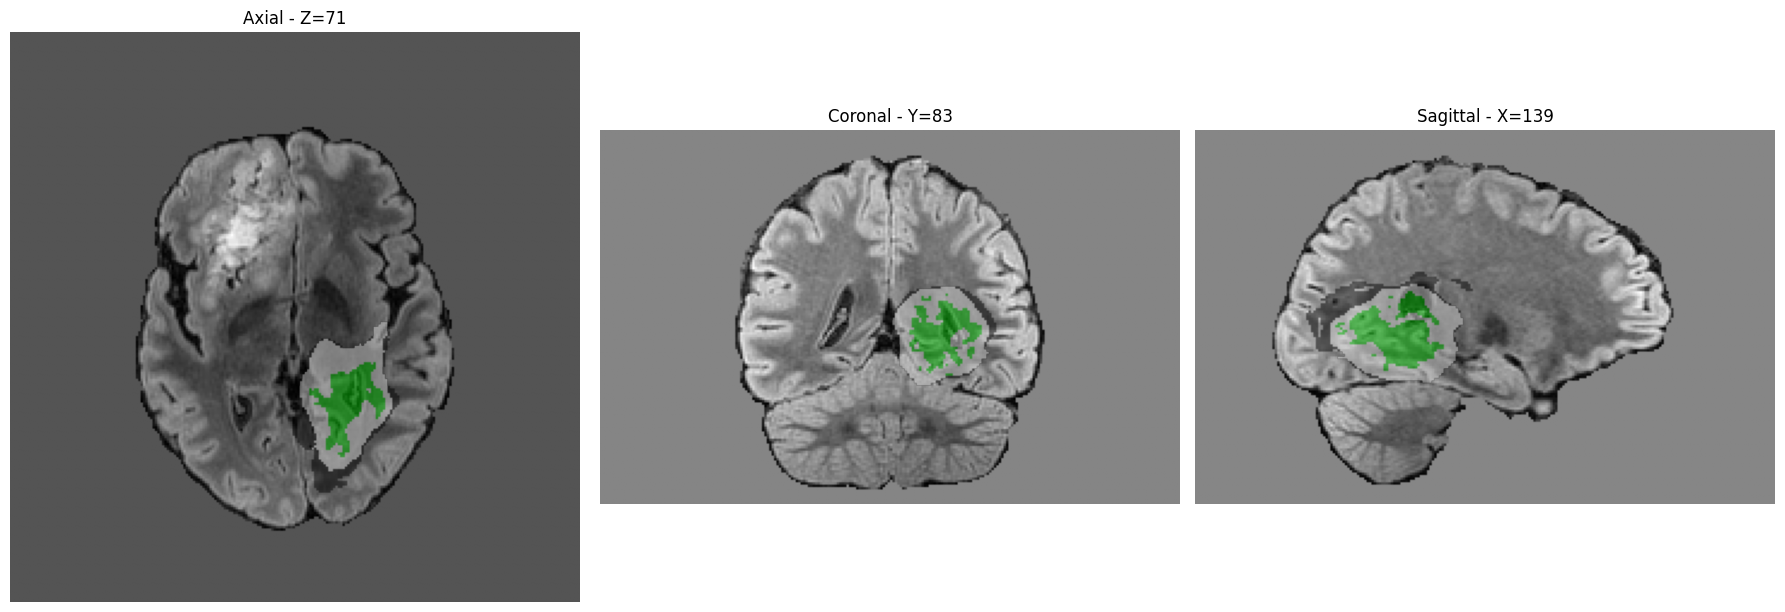

In [57]:
import numpy as np
import matplotlib.pyplot as plt

flair = image_np[0]
gt = converted_mask

# Ground-truth tumour centroid
coords = np.where(gt > 0)

cx, cy, cz = [
    int(np.round(np.mean(axis)))
    for axis in coords
]

print("Ground-truth tumour centroid:", (cx, cy, cz))

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Axial view
axes[0].imshow(flair[:, :, cz].T, cmap="gray", origin="lower")
axes[0].imshow(
    np.ma.masked_where(gt[:, :, cz].T == 0, gt[:, :, cz].T),
    cmap="nipy_spectral", alpha=0.5,
    vmin=1, vmax=3, origin="lower"
)
axes[0].set_title(f"Axial - Z={cz}")

# Coronal view
axes[1].imshow(flair[:, cy, :].T, cmap="gray", origin="lower")
axes[1].imshow(
    np.ma.masked_where(gt[:, cy, :].T == 0, gt[:, cy, :].T),
    cmap="nipy_spectral", alpha=0.5,
    vmin=1, vmax=3, origin="lower"
)
axes[1].set_title(f"Coronal - Y={cy}")

# Sagittal view
axes[2].imshow(flair[cx, :, :].T, cmap="gray", origin="lower")
axes[2].imshow(
    np.ma.masked_where(gt[cx, :, :].T == 0, gt[cx, :, :].T),
    cmap="nipy_spectral", alpha=0.5,
    vmin=1, vmax=3, origin="lower"
)
axes[2].set_title(f"Sagittal - X={cx}")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [58]:
for name in ["t2f", "t1n", "t1c", "t2w", "seg"]:
    nii = nib.load(ras_files[name])

    print(f"\n{name}")
    print("Orientation:", nib.aff2axcodes(nii.affine))
    print("Affine:\n", nii.affine)


t2f
Orientation: ('R', 'A', 'S')
Affine:
 [[   1.    0.    0. -239.]
 [   0.    1.    0.    0.]
 [   0.    0.    1.    0.]
 [   0.    0.    0.    1.]]

t1n
Orientation: ('R', 'A', 'S')
Affine:
 [[   1.    0.    0. -239.]
 [   0.    1.    0.    0.]
 [   0.    0.    1.    0.]
 [   0.    0.    0.    1.]]

t1c
Orientation: ('R', 'A', 'S')
Affine:
 [[   1.    0.    0. -239.]
 [   0.    1.    0.    0.]
 [   0.    0.    1.    0.]
 [   0.    0.    0.    1.]]

t2w
Orientation: ('R', 'A', 'S')
Affine:
 [[   1.    0.    0. -239.]
 [   0.    1.    0.    0.]
 [   0.    0.    1.    0.]
 [   0.    0.    0.    1.]]

seg
Orientation: ('R', 'A', 'S')
Affine:
 [[   1.    0.    0. -239.]
 [   0.    1.    0.    0.]
 [   0.    0.    1.    0.]
 [   0.    0.    0.    1.]]


In [59]:
import nibabel as nib
import numpy as np
import glob

msd_file = glob.glob(
    "/content/drive/MyDrive/BrainTumorProject/"
    "dataset/Task01_BrainTumour/imagesTr/BRATS_*.nii.gz"
)[0]

msd_nii = nib.load(msd_file)
msd_data = msd_nii.get_fdata()

print("MSD image shape:", msd_data.shape)
print("MSD orientation:", nib.aff2axcodes(msd_nii.affine))
print("MSD affine:\n", msd_nii.affine)

print("External image shape:", image_np.shape)
print("External orientation:",
      nib.aff2axcodes(nib.load(ras_files["t2f"]).affine))

MSD image shape: (240, 240, 155, 4)
MSD orientation: ('R', 'A', 'S')
MSD affine:
 [[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]
External image shape: (4, 240, 240, 155)
External orientation: ('R', 'A', 'S')


In [60]:
import os
import nibabel as nib
import numpy as np

for name in ["t2f", "t1n", "t1c", "t2w", "seg"]:
    path = ras_files[name]
    nii = nib.load(path)

    print(
        name,
        "| File:", os.path.basename(path),
        "| Shape:", nii.shape,
        "| Orientation:", nib.aff2axcodes(nii.affine)
    )

t2f | File: BraTS2023_t2f_RAS.nii.gz | Shape: (240, 240, 155) | Orientation: ('R', 'A', 'S')
t1n | File: BraTS2023_t1n_RAS.nii.gz | Shape: (240, 240, 155) | Orientation: ('R', 'A', 'S')
t1c | File: BraTS2023_t1c_RAS.nii.gz | Shape: (240, 240, 155) | Orientation: ('R', 'A', 'S')
t2w | File: BraTS2023_t2w_RAS.nii.gz | Shape: (240, 240, 155) | Orientation: ('R', 'A', 'S')
seg | File: BraTS2023_seg_RAS.nii.gz | Shape: (240, 240, 155) | Orientation: ('R', 'A', 'S')


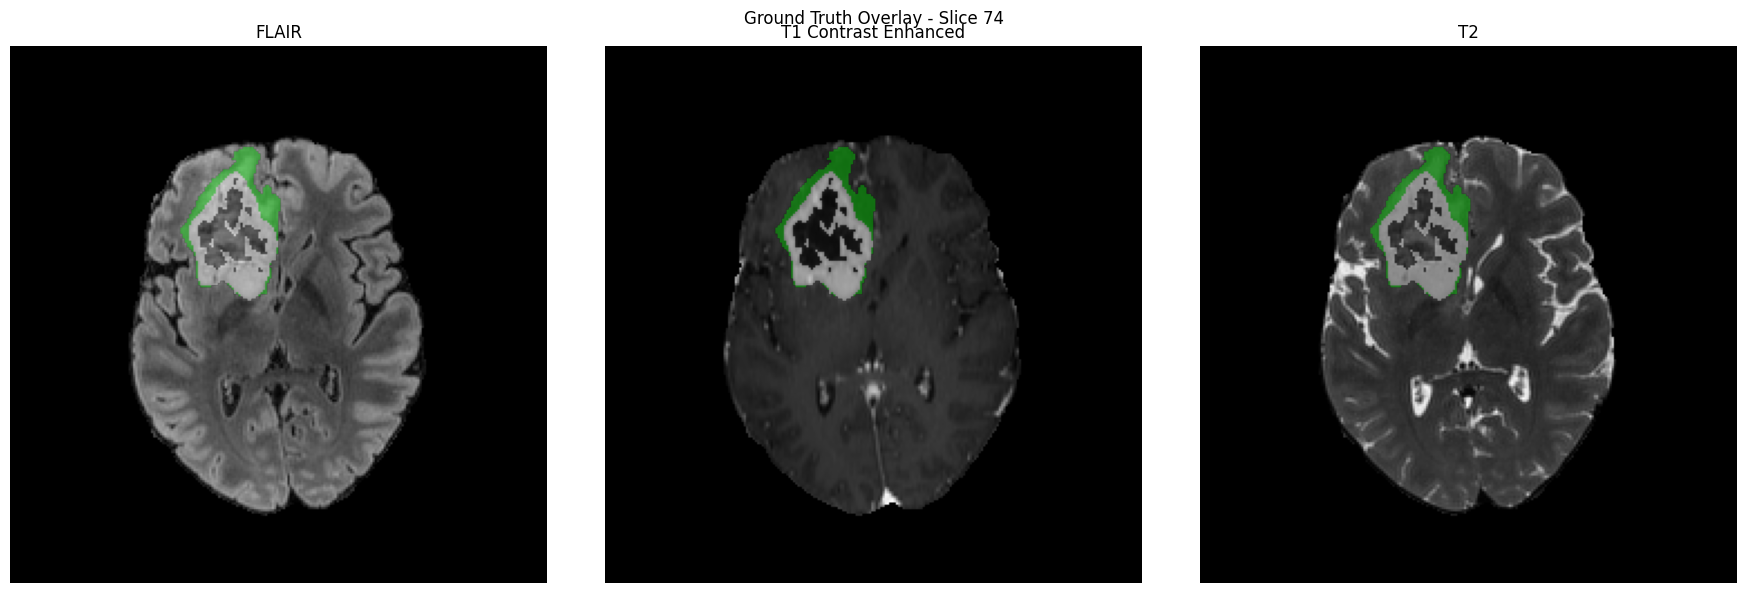

In [61]:
import matplotlib.pyplot as plt
import numpy as np

flair = nib.load(ras_files["t2f"]).get_fdata()
t1ce = nib.load(ras_files["t1c"]).get_fdata()
t2 = nib.load(ras_files["t2w"]).get_fdata()

gt = nib.load(ras_files["seg"]).get_fdata()

# Slice containing the most ground-truth tumour voxels
slice_idx = np.argmax(np.sum(gt > 0, axis=(0, 1)))

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, volume, title in zip(
    axes,
    [flair, t1ce, t2],
    ["FLAIR", "T1 Contrast Enhanced", "T2"]
):
    ax.imshow(volume[:, :, slice_idx].T, cmap="gray", origin="lower")

    ax.imshow(
        np.ma.masked_where(
            gt[:, :, slice_idx].T == 0,
            gt[:, :, slice_idx].T
        ),
        cmap="nipy_spectral",
        alpha=0.5,
        vmin=1,
        vmax=3,
        origin="lower"
    )

    ax.set_title(title)
    ax.axis("off")

plt.suptitle(f"Ground Truth Overlay - Slice {slice_idx}")
plt.tight_layout()
plt.show()

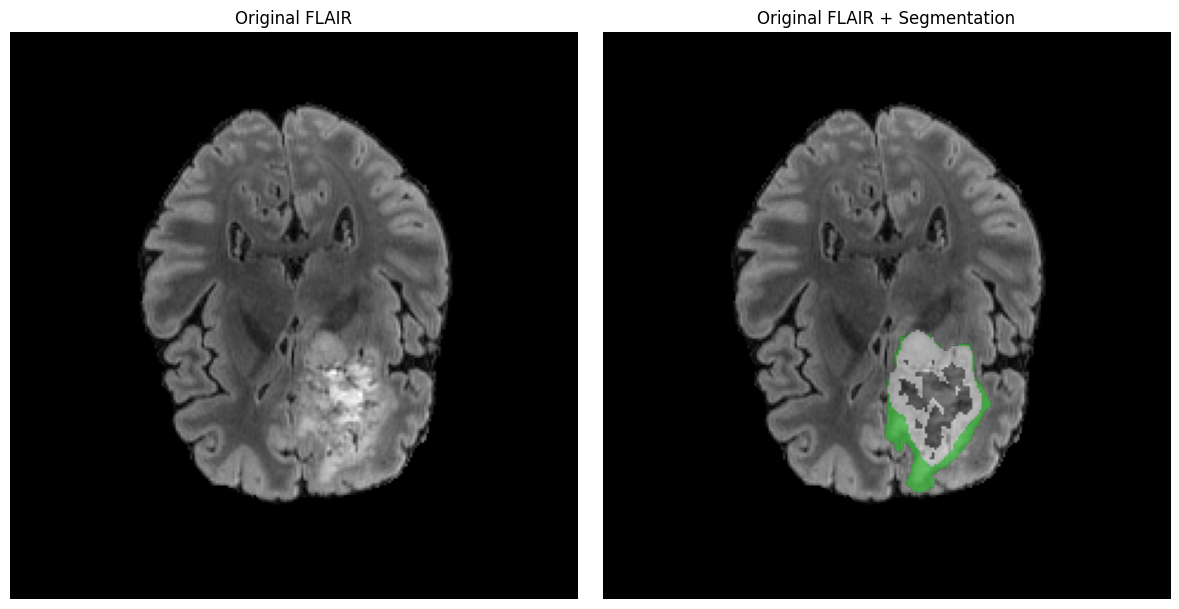

In [62]:
original_flair = nib.load(downloaded["t2f"]).get_fdata()
original_mask = nib.load(downloaded["seg"]).get_fdata()

z = np.argmax(np.sum(original_mask > 0, axis=(0, 1)))

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(original_flair[:, :, z].T, cmap="gray", origin="lower")
axes[0].set_title("Original FLAIR")

axes[1].imshow(original_flair[:, :, z].T, cmap="gray", origin="lower")
axes[1].imshow(
    np.ma.masked_where(
        original_mask[:, :, z].T == 0,
        original_mask[:, :, z].T
    ),
    cmap="nipy_spectral",
    alpha=0.5,
    origin="lower"
)
axes[1].set_title("Original FLAIR + Segmentation")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [63]:
print("Validation loader available:", "val_loader" in globals())

if "val_loader" in globals():
    print("Validation cases:", len(val_loader.dataset))
else:
    print("val_loader is not currently defined.")

Validation loader available: True
Validation cases: 97


In [64]:
import torch
import numpy as np
from monai.inferers import sliding_window_inference

model.eval()

batch = next(iter(val_loader))

images = batch["image"].to(device)
labels = batch["label"].to(device)

print("Image shape:", images.shape)
print("Label shape:", labels.shape)
print("Ground-truth labels:", torch.unique(labels))

with torch.no_grad():
    logits = sliding_window_inference(
        inputs=images,
        roi_size=(96, 96, 96),
        sw_batch_size=1,
        predictor=model,
        overlap=0.25
    )

    preds = torch.argmax(logits, dim=1)

gt = labels[:, 0] if labels.ndim == 5 and labels.shape[1] == 1 else labels

print("Prediction shape:", preds.shape)
print("Predicted labels:", torch.unique(preds))

Image shape: torch.Size([1, 4, 240, 240, 155])
Label shape: torch.Size([1, 1, 240, 240, 155])
Ground-truth labels: metatensor([0., 1., 2., 3.])
Prediction shape: torch.Size([1, 240, 240, 155])
Predicted labels: metatensor([0, 1, 2, 3])


In [65]:
def dice_score(pred, target, label):
    p = pred == label
    t = target == label

    intersection = (p & t).sum().item()
    denominator = p.sum().item() + t.sum().item()

    if denominator == 0:
        return 1.0

    return 2.0 * intersection / denominator


class_names = {
    1: "Edema",
    2: "Non-enhancing tumour",
    3: "Enhancing tumour"
}

for label, name in class_names.items():
    score = dice_score(
        preds[0],
        gt[0],
        label
    )

    print(f"{name}: {score:.4f}")

Edema: 0.7608
Non-enhancing tumour: 0.6955
Enhancing tumour: 0.6906


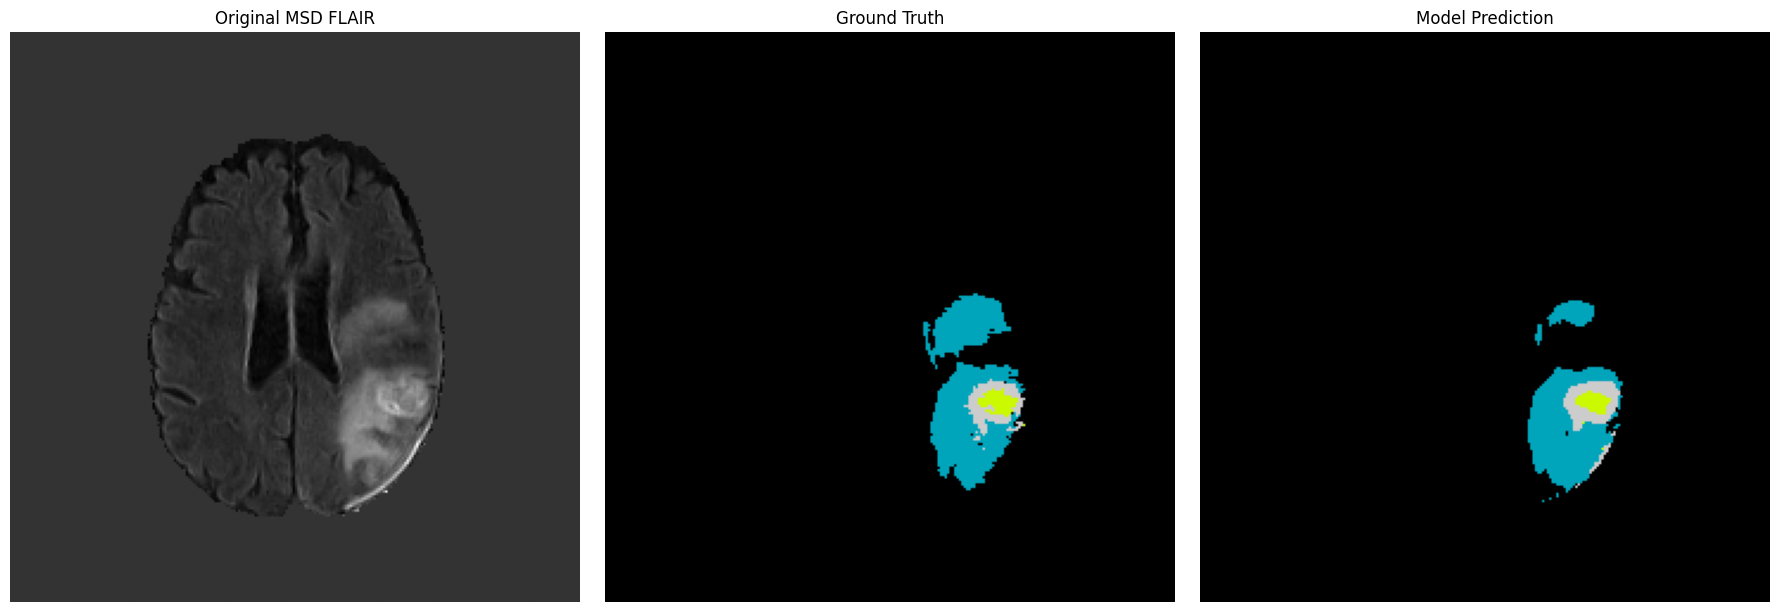

In [66]:
import matplotlib.pyplot as plt

image_np = images[0, 0].cpu().numpy()
gt_np = gt[0].cpu().numpy()
pred_np = preds[0].cpu().numpy()

# Select slice with maximum ground-truth tumour area
slice_idx = np.argmax(
    np.sum(gt_np > 0, axis=(0, 1))
)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(
    image_np[:, :, slice_idx].T,
    cmap="gray",
    origin="lower"
)
axes[0].set_title("Original MSD FLAIR")

axes[1].imshow(
    gt_np[:, :, slice_idx].T,
    cmap="nipy_spectral",
    vmin=0,
    vmax=3,
    origin="lower"
)
axes[1].set_title("Ground Truth")

axes[2].imshow(
    pred_np[:, :, slice_idx].T,
    cmap="nipy_spectral",
    vmin=0,
    vmax=3,
    origin="lower"
)
axes[2].set_title("Model Prediction")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [67]:
import torch
import numpy as np
from monai.inferers import sliding_window_inference

model.eval()

dice_results = {
    1: [],
    2: [],
    3: []
}

def calculate_case_dice(pred, target, label):
    p = pred == label
    t = target == label

    intersection = np.logical_and(p, t).sum()
    denominator = p.sum() + t.sum()

    if denominator == 0:
        return None

    return 2.0 * intersection / denominator


with torch.no_grad():

    for batch_idx, batch in enumerate(val_loader):

        images = batch["image"].to(device)
        labels = batch["label"].to(device)

        logits = sliding_window_inference(
            inputs=images,
            roi_size=(96, 96, 96),
            sw_batch_size=1,
            predictor=model,
            overlap=0.25
        )

        preds = torch.argmax(logits, dim=1)

        if labels.ndim == 5 and labels.shape[1] == 1:
            labels = labels[:, 0]

        preds = preds.cpu().numpy()
        labels = labels.cpu().numpy()

        for i in range(preds.shape[0]):
            for label in [1, 2, 3]:

                score = calculate_case_dice(
                    preds[i],
                    labels[i],
                    label
                )

                if score is not None:
                    dice_results[label].append(score)

        print(
            f"Processed batch {batch_idx + 1}/{len(val_loader)}"
        )


class_names = {
    1: "Edema",
    2: "Non-enhancing tumour",
    3: "Enhancing tumour"
}

print("\nCOMPLETE VALIDATION RESULTS")

class_means = []

for label, name in class_names.items():

    scores = np.array(dice_results[label])

    mean_dice = scores.mean() if len(scores) else float("nan")
    std_dice = scores.std() if len(scores) else float("nan")

    class_means.append(mean_dice)

    print(f"\n{name}")
    print(f"Mean Dice: {mean_dice:.4f}")
    print(f"Std Dice:  {std_dice:.4f}")
    print(f"Cases evaluated: {len(scores)}")

print("\nOverall Mean Dice:", np.nanmean(class_means))

Processed batch 1/97
Processed batch 2/97
Processed batch 3/97
Processed batch 4/97
Processed batch 5/97
Processed batch 6/97
Processed batch 7/97
Processed batch 8/97
Processed batch 9/97
Processed batch 10/97
Processed batch 11/97
Processed batch 12/97
Processed batch 13/97
Processed batch 14/97
Processed batch 15/97
Processed batch 16/97
Processed batch 17/97
Processed batch 18/97
Processed batch 19/97
Processed batch 20/97
Processed batch 21/97
Processed batch 22/97
Processed batch 23/97
Processed batch 24/97
Processed batch 25/97
Processed batch 26/97
Processed batch 27/97
Processed batch 28/97
Processed batch 29/97
Processed batch 30/97
Processed batch 31/97
Processed batch 32/97
Processed batch 33/97
Processed batch 34/97
Processed batch 35/97
Processed batch 36/97
Processed batch 37/97
Processed batch 38/97
Processed batch 39/97
Processed batch 40/97
Processed batch 41/97
Processed batch 42/97
Processed batch 43/97
Processed batch 44/97
Processed batch 45/97
Processed batch 46/

In [68]:
# Phase-1:
import os

PROJECT_DIR = "/content/drive/MyDrive/BrainTumorProject"

CHECKPOINT_PATH = os.path.join(
    PROJECT_DIR, "checkpoints", "best_model_v3.pth"
)

PREDICTION_DIR = os.path.join(
    PROJECT_DIR, "predictions"
)

VISUALIZATION_DIR = os.path.join(
    PROJECT_DIR, "visualizations"
)

INFERENCE_DIR = os.path.join(
    PROJECT_DIR, "inference"
)

for folder in [
    PREDICTION_DIR,
    VISUALIZATION_DIR,
    INFERENCE_DIR
]:
    os.makedirs(folder, exist_ok=True)

print("Project directories created.")
print("Checkpoint exists:", os.path.exists(CHECKPOINT_PATH))

Project directories created.
Checkpoint exists: True


In [69]:
# Step 2: Create a reusable model-loading function
import torch
import monai

from monai.networks.nets import UNet

def load_brain_tumor_model(checkpoint_path):

    device = torch.device(
        "cuda" if torch.cuda.is_available() else "cpu"
    )

    print("Device:", device)
    print("MONAI:", monai.__version__)
    print("PyTorch:", torch.__version__)

    model = UNet(
        spatial_dims=3,
        in_channels=4,
        out_channels=4,
        channels=(16, 32, 64, 128),
        strides=(2, 2, 2),
        num_res_units=2
    ).to(device)

    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=False
    )

    saved_state = checkpoint["model_state_dict"]
    current_state = model.state_dict()

    saved_keys = list(saved_state.keys())
    current_keys = list(current_state.keys())

    assert len(saved_keys) == len(current_keys), (
        "Checkpoint and model parameter counts differ."
    )

    for old_key, new_key in zip(saved_keys, current_keys):
        assert saved_state[old_key].shape == current_state[new_key].shape, (
            f"Parameter mismatch: {old_key} -> {new_key}"
        )

    remapped_state = {
        new_key: saved_state[old_key]
        for old_key, new_key in zip(saved_keys, current_keys)
    }

    model.load_state_dict(remapped_state, strict=True)
    model.eval()

    print("Model loaded successfully.")
    print("Checkpoint epoch:", checkpoint["epoch"])
    print("Best validation Dice:", checkpoint["best_dice"])

    return model, device, checkpoint


model, device, checkpoint = load_brain_tumor_model(
    CHECKPOINT_PATH
)

Device: cpu
MONAI: 1.6.2
PyTorch: 2.14.1+cpu
Model loaded successfully.
Checkpoint epoch: 40
Best validation Dice: 0.70013028383255


In [70]:
# Step 2: Create a reusable model-loading function
import torch
import monai

from monai.networks.nets import UNet

def load_brain_tumor_model(checkpoint_path):

    device = torch.device(
        "cuda" if torch.cuda.is_available() else "cpu"
    )

    print("Device:", device)
    print("MONAI:", monai.__version__)
    print("PyTorch:", torch.__version__)

    model = UNet(
        spatial_dims=3,
        in_channels=4,
        out_channels=4,
        channels=(16, 32, 64, 128),
        strides=(2, 2, 2),
        num_res_units=2
    ).to(device)

    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=False
    )

    saved_state = checkpoint["model_state_dict"]
    current_state = model.state_dict()

    saved_keys = list(saved_state.keys())
    current_keys = list(current_state.keys())

    assert len(saved_keys) == len(current_keys), (
        "Checkpoint and model parameter counts differ."
    )

    for old_key, new_key in zip(saved_keys, current_keys):
        assert saved_state[old_key].shape == current_state[new_key].shape, (
            f"Parameter mismatch: {old_key} -> {new_key}"
        )

    remapped_state = {
        new_key: saved_state[old_key]
        for old_key, new_key in zip(saved_keys, current_keys)
    }

    model.load_state_dict(remapped_state, strict=True)
    model.eval()

    print("Model loaded successfully.")
    print("Checkpoint epoch:", checkpoint["epoch"])
    print("Best validation Dice:", checkpoint["best_dice"])

    return model, device, checkpoint


model, device, checkpoint = load_brain_tumor_model(
    CHECKPOINT_PATH
)

Device: cpu
MONAI: 1.6.2
PyTorch: 2.14.1+cpu
Model loaded successfully.
Checkpoint epoch: 40
Best validation Dice: 0.70013028383255


In [71]:
# Step 3: Create the preprocessing function
import numpy as np
import torch

from monai.transforms import NormalizeIntensity

def preprocess_mri(image):

    image = np.asarray(image, dtype=np.float32)

    if image.ndim != 4 or image.shape[0] != 4:
        raise ValueError(
            "Expected MRI shape (4, X, Y, Z), "
            f"received {image.shape}"
        )

    if not np.isfinite(image).all():
        raise ValueError("MRI contains NaN or infinite values.")

    normalizer = NormalizeIntensity(
        nonzero=True,
        channel_wise=True
    )

    normalized = normalizer(image.copy())

    input_tensor = torch.from_numpy(
        np.ascontiguousarray(normalized, dtype=np.float32)
    )

    input_tensor = input_tensor.unsqueeze(0)

    return input_tensor.to(device)

In [72]:
# Step 4: Create the reusable prediction function
from monai.inferers import sliding_window_inference

def predict_tumor(image, model, device):

    input_tensor = preprocess_mri(image)

    model.eval()

    with torch.inference_mode():

        logits = sliding_window_inference(
            inputs=input_tensor,
            roi_size=(96, 96, 96),
            sw_batch_size=1,
            predictor=model,
            overlap=0.25
        )

        prediction = torch.argmax(
            logits, dim=1
        )

    prediction = prediction.squeeze(0).cpu().numpy()
    prediction = prediction.astype(np.uint8)

    return prediction


print("Inference functions created.")

Inference functions created.


In [73]:
# Step 5: Test the inference pipeline on an original MSD validation case
import nibabel as nib
import json
import os
import numpy as np

SPLIT_DIR = os.path.join(
    PROJECT_DIR, "version3", "split"
)

with open(
    os.path.join(SPLIT_DIR, "val_files.json"), "r"
) as f:
    val_records = json.load(f)

# Select one validation case
test_record = val_records[0]

image_path = test_record["image"]
label_path = test_record["label"]

print("Validation image:", image_path)
print("Validation label:", label_path)

# Load original MSD 4D MRI
image_nii = nib.load(image_path)
image_data = image_nii.get_fdata().astype(np.float32)

print("Original image shape:", image_data.shape)

if image_data.ndim != 4 or image_data.shape[-1] != 4:
    raise ValueError(
        "Expected MSD image shape (X, Y, Z, 4). "
        "Check the image layout before inference."
    )

# Convert from (X, Y, Z, 4) to (4, X, Y, Z)
image_data = np.moveaxis(image_data, -1, 0)

# Run prediction
prediction = predict_tumor(
    image_data,
    model,
    device
)

print("Prediction shape:", prediction.shape)
print(
    "Predicted labels and voxel counts:",
    np.unique(prediction, return_counts=True)
)

Validation image: /content/drive/MyDrive/BrainTumorProject/dataset/Task01_BrainTumour/imagesTr/BRATS_419.nii.gz
Validation label: /content/drive/MyDrive/BrainTumorProject/dataset/Task01_BrainTumour/labelsTr/BRATS_419.nii.gz
Original image shape: (240, 240, 155, 4)
Prediction shape: (240, 240, 155)
Predicted labels and voxel counts: (array([0, 1, 2, 3], dtype=uint8), array([8830821,   69782,    3728,   23669]))


In [74]:
# Step 6: Save the predicted segmentation as NIfTI
case_name = os.path.basename(image_path).replace(
    ".nii.gz", ""
)

output_path = os.path.join(
    PREDICTION_DIR,
    f"{case_name}_prediction.nii.gz"
)

prediction_nii = nib.Nifti1Image(
    prediction,
    image_nii.affine,
    image_nii.header.copy()
)

prediction_nii.set_data_dtype(np.uint8)

nib.save(prediction_nii, output_path)

print("Prediction saved successfully:")
print(output_path)

Prediction saved successfully:
/content/drive/MyDrive/BrainTumorProject/predictions/BRATS_419_prediction.nii.gz


In [75]:
print("Inference pipeline verification")
print("-------------------------------")
print("Model:", type(model).__name__)
print("Device:", device)
print("Input channels:", image_data.shape[0])
print("Prediction dimensions:", prediction.shape)
print("Output file exists:", os.path.exists(output_path))
print("Output file size (MB):",
      round(os.path.getsize(output_path) / (1024 * 1024), 2))

Inference pipeline verification
-------------------------------
Model: UNet
Device: cpu
Input channels: 4
Prediction dimensions: (240, 240, 155)
Output file exists: True
Output file size (MB): 0.06


In [ ]:
# # Phase 2 – Tumour segmentation visualization
#    Phase 2 objectives
# 1. Display the original MRI slices.
# 2. Overlay predicted tumour segmentation.
# 3. Distinguish the three tumour classes using separate colours.
# 4. Navigate axial, coronal and sagittal views.
# 5. Display tumour volume and class-wise statistics.
# 6. Save visualization images for your research report.

In [76]:
# Step 1: Prepare the visualization input
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt
import os

# image_data: (4, X, Y, Z)
# prediction: (X, Y, Z)

flair = image_data[0]

print("FLAIR shape:", flair.shape)
print("Prediction shape:", prediction.shape)
print("Prediction classes:", np.unique(prediction))

assert flair.shape == prediction.shape

FLAIR shape: (240, 240, 155)
Prediction shape: (240, 240, 155)
Prediction classes: [0 1 2 3]


In [77]:
# Step 2: Create a reusable 3D slice visualization function
import matplotlib.pyplot as plt
import numpy as np

# Segmentation colours
COLORS = {
    1: "#E5484D",  # Edema
    2: "#E5A000",  # Non-enhancing tumour
    3: "#2685E8"   # Enhancing tumour
}

def visualize_segmentation(flair, prediction, save_path=None):

    if flair.shape != prediction.shape:
        raise ValueError("FLAIR and prediction shapes must match.")

    # Find slices with the largest tumour area
    axial_idx = np.argmax(
        np.sum(prediction > 0, axis=(0, 1))
    )

    coronal_idx = np.argmax(
        np.sum(prediction > 0, axis=(0, 2))
    )

    sagittal_idx = np.argmax(
        np.sum(prediction > 0, axis=(1, 2))
    )

    fig, axes = plt.subplots(2, 3, figsize=(18, 11))

    views = [
        (flair[:, :, axial_idx].T,
         prediction[:, :, axial_idx].T,
         "Axial", f"Z = {axial_idx}"),

        (flair[:, coronal_idx, :].T,
         prediction[:, coronal_idx, :].T,
         "Coronal", f"Y = {coronal_idx}"),

        (flair[sagittal_idx, :, :].T,
         prediction[sagittal_idx, :, :].T,
         "Sagittal", f"X = {sagittal_idx}")
    ]

    for i, (mri, mask, name, position) in enumerate(views):

        # Original MRI
        axes[0, i].imshow(
            mri,
            cmap="gray",
            origin="lower"
        )
        axes[0, i].set_title(f"{name} - MRI ({position})")

        # MRI with tumour overlay
        axes[1, i].imshow(
            mri,
            cmap="gray",
            origin="lower"
        )

        for label, color in COLORS.items():
            class_mask = np.ma.masked_where(
                mask != label,
                mask
            )

            axes[1, i].imshow(
                class_mask,
                cmap=plt.matplotlib.colors.ListedColormap([color]),
                vmin=label,
                vmax=label,
                alpha=0.65,
                origin="lower"
            )

        axes[1, i].set_title(f"{name} - Segmentation Overlay")

        for row in range(2):
            axes[row, i].axis("off")

    fig.suptitle(
        "3D Brain Tumour Segmentation Visualization",
        fontsize=17
    )

    plt.tight_layout()

    if save_path:
        plt.savefig(
            save_path,
            dpi=300,
            bbox_inches="tight"
        )

    plt.show()

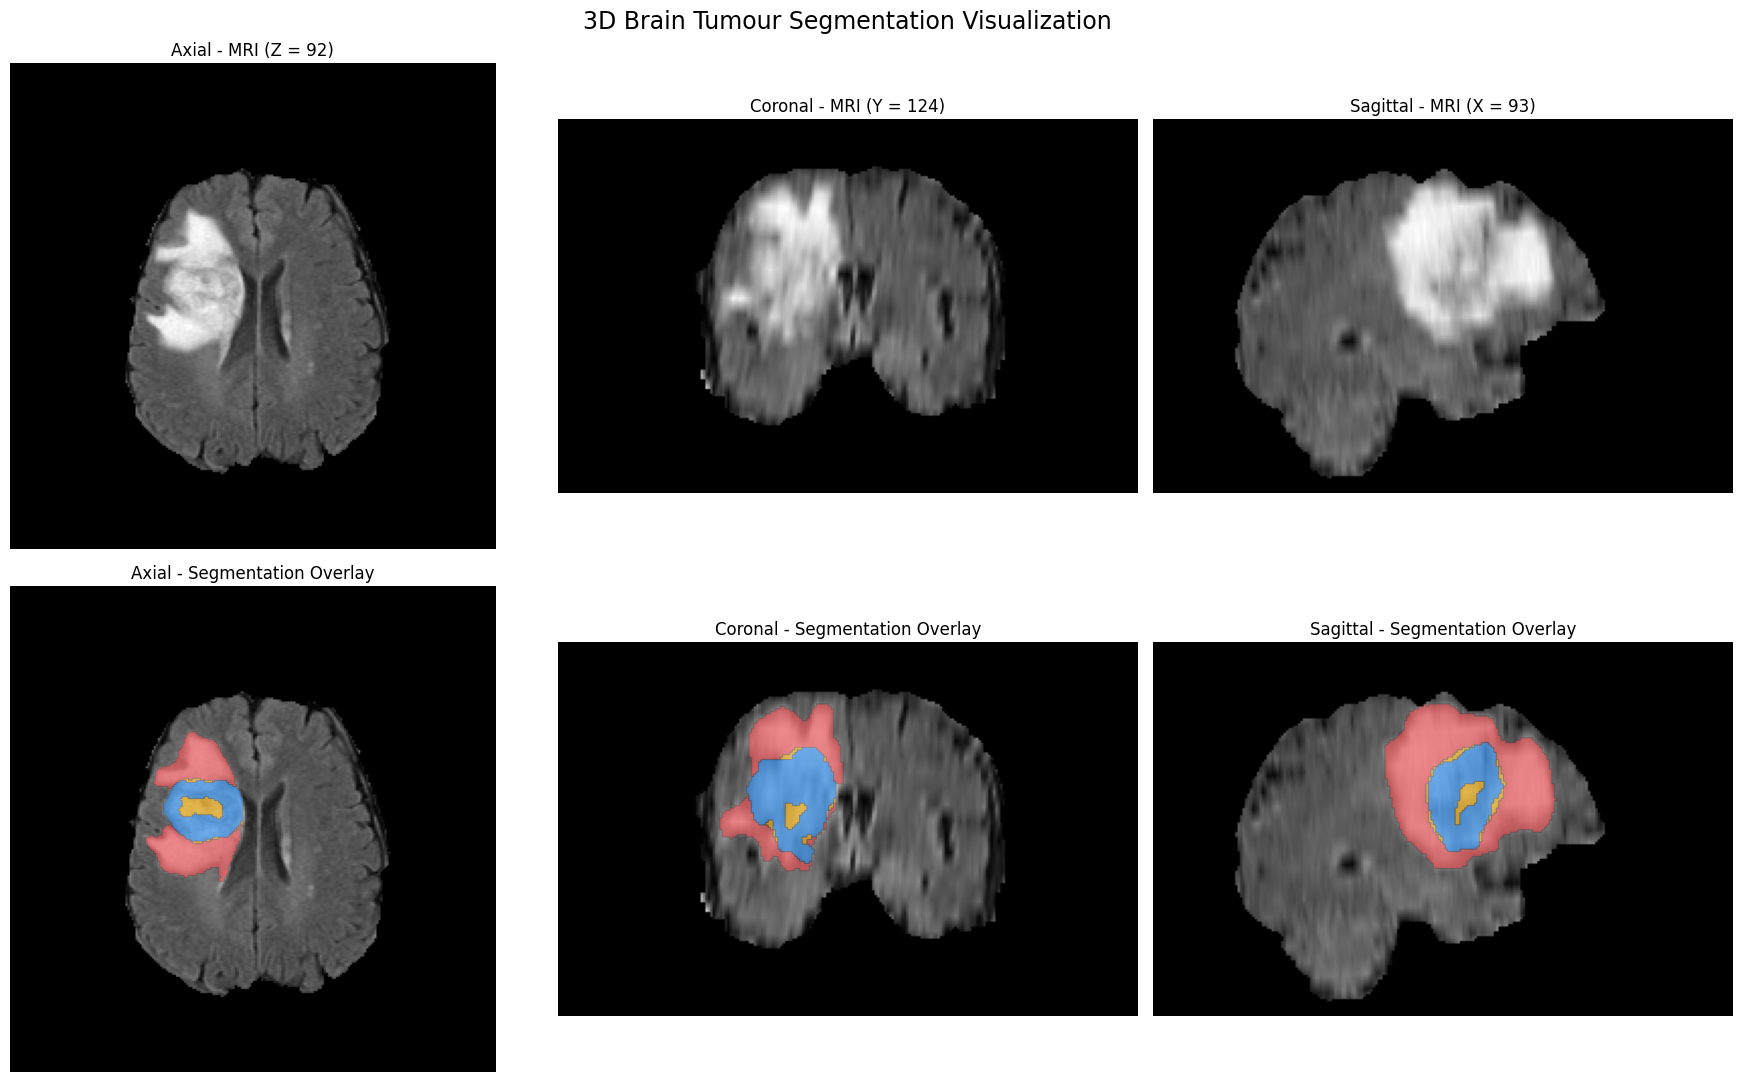

Visualization saved: /content/drive/MyDrive/BrainTumorProject/visualizations/tumor_segmentation_views.png


In [78]:
visualization_path = os.path.join(
    VISUALIZATION_DIR,
    "tumor_segmentation_views.png"
)

visualize_segmentation(
    flair,
    prediction,
    save_path=visualization_path
)

print("Visualization saved:", visualization_path)

In [79]:
# Step 3: Calculate tumour volumes
def calculate_tumor_statistics(prediction, nii_path):

    nii = nib.load(nii_path)
    spacing = nii.header.get_zooms()[:3]

    voxel_volume = np.prod(spacing)

    classes = {
        1: "Edema",
        2: "Non-enhancing tumour",
        3: "Enhancing tumour"
    }

    print("Tumour Volume Statistics")
    print("------------------------")

    total_voxels = 0

    for label, name in classes.items():

        voxel_count = int(np.sum(prediction == label))
        volume_mm3 = voxel_count * voxel_volume
        volume_cm3 = volume_mm3 / 1000

        total_voxels += voxel_count

        print(f"\n{name}")
        print("Voxel count:", f"{voxel_count:,}")
        print("Volume (mm³):", round(volume_mm3, 2))
        print("Volume (cm³):", round(volume_cm3, 3))

    total_volume_cm3 = total_voxels * voxel_volume / 1000

    print("\nTotal tumour volume:", round(total_volume_cm3, 3), "cm³")

In [80]:
calculate_tumor_statistics(
    prediction,
    image_path
)

Tumour Volume Statistics
------------------------

Edema
Voxel count: 69,782
Volume (mm³): 69782.0
Volume (cm³): 69.782

Non-enhancing tumour
Voxel count: 3,728
Volume (mm³): 3728.0
Volume (cm³): 3.728

Enhancing tumour
Voxel count: 23,669
Volume (mm³): 23669.0
Volume (cm³): 23.669

Total tumour volume: 97.179 cm³


In [81]:
# Step 4: Interactive slice navigation
# After confirming the static visualizations, we will add interactive controls using ipywidgets:
# - Axial, coronal and sagittal selection.
# - Slice-number slider.
# - Original MRI and segmentation overlay.
# - Class visibility controls.
# - Live slice navigation.

import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

# Segmentation colours
cmap = ListedColormap([
    "none",
    "#E5484D",  # Edema
    "#E5A000",  # Non-enhancing tumour
    "#2685E8"   # Enhancing tumour
])
cmap.set_bad(alpha=0)

def show_slice(view, slice_idx):
    if view == "Axial":
        mri_slice = flair[:, :, slice_idx].T
        mask_slice = prediction[:, :, slice_idx].T

    elif view == "Coronal":
        mri_slice = flair[:, slice_idx, :].T
        mask_slice = prediction[:, slice_idx, :].T

    else:  # Sagittal
        mri_slice = flair[slice_idx, :, :].T
        mask_slice = prediction[slice_idx, :, :].T

    masked = np.ma.masked_where(mask_slice == 0, mask_slice)

    fig, ax = plt.subplots(figsize=(8, 8))

    ax.imshow(mri_slice, cmap="gray", origin="lower")
    ax.imshow(
        masked,
        cmap=cmap,
        vmin=0,
        vmax=3,
        alpha=0.65,
        origin="lower",
        interpolation="nearest"
    )

    ax.set_title(f"{view} View – Slice {slice_idx}")
    ax.axis("off")

    legend = [
        Patch(color="#E5484D", label="Edema"),
        Patch(color="#E5A000", label="Non-enhancing tumour"),
        Patch(color="#2685E8", label="Enhancing tumour")
    ]

    ax.legend(handles=legend, loc="upper right")
    plt.show()


def interactive_viewer(view="Axial"):
    dimensions = {
        "Axial": prediction.shape[2],
        "Coronal": prediction.shape[1],
        "Sagittal": prediction.shape[0]
    }

    axis = {"Axial": 2, "Coronal": 1, "Sagittal": 0}[view]
    tumour_counts = np.sum(prediction > 0, axis=tuple(
        i for i in range(3) if i != axis
    ))
    default_idx = int(np.argmax(tumour_counts))

    widgets.interact(
        show_slice,
        view=widgets.fixed(view),
        slice_idx=widgets.IntSlider(
            min=0,
            max=dimensions[view] - 1,
            value=default_idx,
            description="Slice:",
            continuous_update=False
        )
    )

In [82]:
interactive_viewer("Axial")

interactive(children=(IntSlider(value=92, continuous_update=False, description='Slice:', max=154), Output()), …

In [83]:
interactive_viewer("Coronal")

interactive(children=(IntSlider(value=124, continuous_update=False, description='Slice:', max=239), Output()),…

In [84]:
interactive_viewer("Sagittal")

interactive(children=(IntSlider(value=93, continuous_update=False, description='Slice:', max=239), Output()), …

In [85]:
!pip install -q monai scipy scikit-learn pandas

In [86]:
# Step 2 – Define evaluation metrics
# We will calculate metrics separately for each tumour class:
# Metric	Purpose
# Dice Score	Measures overlap between predicted and actual masks
# IoU	Measures intersection over union
# Precision	Measures how many predicted tumour voxels are correct
# Recall	Measures how many actual tumour voxels are detected
# HD95	Measures boundary-distance error

import numpy as np
from scipy.spatial.distance import directed_hausdorff

def calculate_metrics(prediction, ground_truth, label):
    pred = prediction == label
    gt = ground_truth == label

    tp = np.logical_and(pred, gt).sum()
    fp = np.logical_and(pred, ~gt).sum()
    fn = np.logical_and(~pred, gt).sum()

    dice = (2 * tp) / (2 * tp + fp + fn + 1e-8)
    iou = tp / (tp + fp + fn + 1e-8)
    precision = tp / (tp + fp + 1e-8)
    recall = tp / (tp + fn + 1e-8)

    return {
        "Dice": dice,
        "IoU": iou,
        "Precision": precision,
        "Recall": recall
    }

In [87]:
import json
import os
import nibabel as nib
import pandas as pd

with open(
    "/content/drive/MyDrive/BrainTumorProject/version3/split/val_files.json"
) as f:
    val_files = json.load(f)

# Adapt these keys if your JSON uses a different structure.
print("Validation file example:", val_files[0])

Validation file example: {'image': '/content/drive/MyDrive/BrainTumorProject/dataset/Task01_BrainTumour/imagesTr/BRATS_419.nii.gz', 'label': '/content/drive/MyDrive/BrainTumorProject/dataset/Task01_BrainTumour/labelsTr/BRATS_419.nii.gz'}


In [88]:
# Phase 3 – Quantitative model evaluation
import os
import json
import torch
import numpy as np
import pandas as pd

from monai.transforms import (
    Compose,
    LoadImaged,
    EnsureChannelFirstd,
    NormalizeIntensityd,
    EnsureTyped
)
from monai.inferers import sliding_window_inference

# Load validation split
val_json = "/content/drive/MyDrive/BrainTumorProject/version3/split/val_files.json"

with open(val_json, "r") as f:
    val_files = json.load(f)

# Same preprocessing used during training/validation
val_transform = Compose([
    LoadImaged(keys=["image", "label"]),
    EnsureChannelFirstd(keys=["image", "label"]),
    NormalizeIntensityd(
        keys=["image"],
        nonzero=True,
        channel_wise=True
    ),
    EnsureTyped(keys=["image", "label"])
])

model.eval()

class_names = {
    1: "Edema",
    2: "Non-enhancing tumour",
    3: "Enhancing tumour"
}

results = []

for i, item in enumerate(val_files):

    data = val_transform(item)

    image = data["image"].unsqueeze(0).to(device)
    ground_truth = data["label"][0].cpu().numpy().astype(np.uint8)

    with torch.no_grad():
        logits = sliding_window_inference(
            inputs=image,
            roi_size=(96, 96, 96),
            sw_batch_size=1,
            predictor=model,
            overlap=0.25
        )

        prediction = torch.argmax(logits, dim=1)[0]
        prediction = prediction.cpu().numpy().astype(np.uint8)

    if prediction.shape != ground_truth.shape:
        raise ValueError(
            f"Shape mismatch in case {i}: "
            f"{prediction.shape} vs {ground_truth.shape}"
        )

    case_result = {"Case": os.path.basename(item["image"])}

    for label, name in class_names.items():

        pred_mask = prediction == label
        gt_mask = ground_truth == label

        tp = np.logical_and(pred_mask, gt_mask).sum()
        fp = np.logical_and(pred_mask, ~gt_mask).sum()
        fn = np.logical_and(~pred_mask, gt_mask).sum()

        dice = (2 * tp) / (2 * tp + fp + fn + 1e-8)
        iou = tp / (tp + fp + fn + 1e-8)
        precision = tp / (tp + fp + 1e-8)
        recall = tp / (tp + fn + 1e-8)

        case_result[f"{name}_Dice"] = dice
        case_result[f"{name}_IoU"] = iou
        case_result[f"{name}_Precision"] = precision
        case_result[f"{name}_Recall"] = recall

    results.append(case_result)

    print(f"Processed case {i + 1}/{len(val_files)}")

print("\nEvaluation completed.")

Processed case 1/97
Processed case 2/97
Processed case 3/97
Processed case 4/97
Processed case 5/97
Processed case 6/97
Processed case 7/97
Processed case 8/97
Processed case 9/97
Processed case 10/97
Processed case 11/97
Processed case 12/97
Processed case 13/97
Processed case 14/97
Processed case 15/97
Processed case 16/97
Processed case 17/97
Processed case 18/97
Processed case 19/97
Processed case 20/97
Processed case 21/97
Processed case 22/97
Processed case 23/97
Processed case 24/97
Processed case 25/97
Processed case 26/97
Processed case 27/97
Processed case 28/97
Processed case 29/97
Processed case 30/97
Processed case 31/97
Processed case 32/97
Processed case 33/97
Processed case 34/97
Processed case 35/97
Processed case 36/97
Processed case 37/97
Processed case 38/97
Processed case 39/97
Processed case 40/97
Processed case 41/97
Processed case 42/97
Processed case 43/97
Processed case 44/97
Processed case 45/97
Processed case 46/97
Processed case 47/97
Processed case 48/97
P

In [89]:
# Step 2 – Calculate average performance
df = pd.DataFrame(results)

metric_names = ["Dice", "IoU", "Precision", "Recall"]

summary = {}

for metric in metric_names:
    for name in class_names.values():

        column = f"{name}_{metric}"

        summary[f"{name}_{metric}"] = {
            "Mean": df[column].mean(),
            "Std": df[column].std()
        }

summary_df = pd.DataFrame(summary).T
summary_df.columns = ["Mean", "Std"]

print("\nVALIDATION PERFORMANCE")
display(summary_df.round(4))


VALIDATION PERFORMANCE


,Mean,Std
Edema_Dice,0.7840,0.1138
Non-enhancing tumour_Dice,0.5725,0.2230
Enhancing tumour_Dice,0.7390,0.2354
Edema_IoU,0.6576,0.1407
Non-enhancing tumour_IoU,0.4333,0.2113
Enhancing tumour_IoU,0.6300,0.2417
Edema_Precision,0.7986,0.1363
Non-enhancing tumour_Precision,0.6513,0.2380
Enhancing tumour_Precision,0.7192,0.2640
Edema_Recall,0.7865,0.1261


In [90]:
# Step 3 – Calculate macro-average Dice
dice_columns = [
    "Edema_Dice",
    "Non-enhancing tumour_Dice",
    "Enhancing tumour_Dice"
]

df["Macro_Dice"] = df[dice_columns].mean(axis=1)

print("Overall Macro Dice:", round(df["Macro_Dice"].mean(), 4))
print("Standard Deviation:", round(df["Macro_Dice"].std(), 4))

Overall Macro Dice: 0.6985
Standard Deviation: 0.1436


In [91]:
# Step 4 – Save evaluation results
output_dir = "/content/drive/MyDrive/BrainTumorProject/evaluation"

os.makedirs(output_dir, exist_ok=True)

df.to_csv(
    os.path.join(output_dir, "validation_case_metrics.csv"),
    index=False
)

summary_df.to_csv(
    os.path.join(output_dir, "validation_summary.csv")
)

print("Evaluation results saved successfully.")

Evaluation results saved successfully.


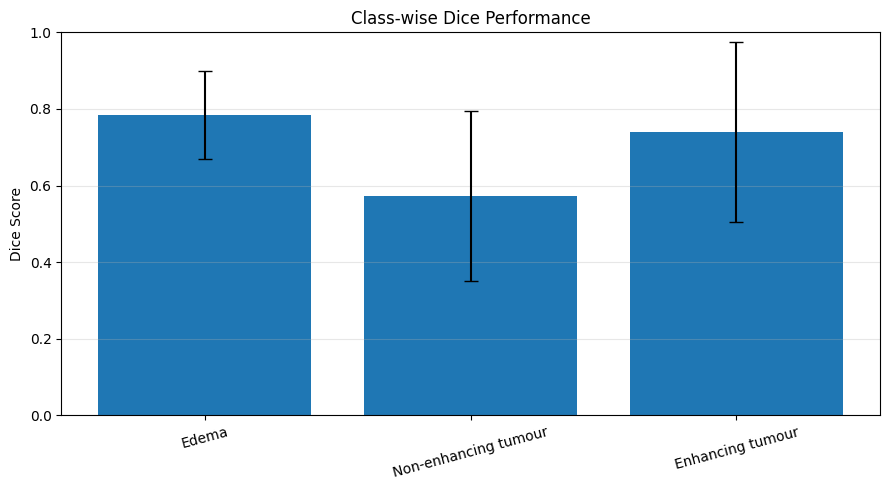

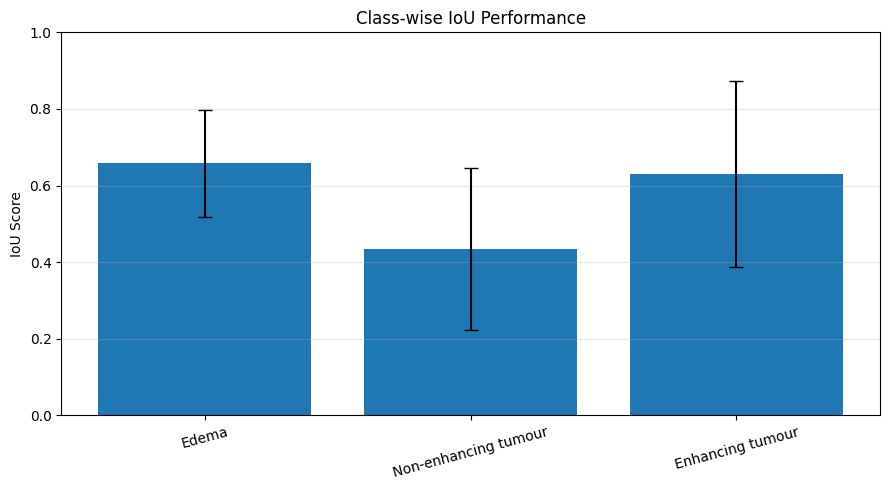

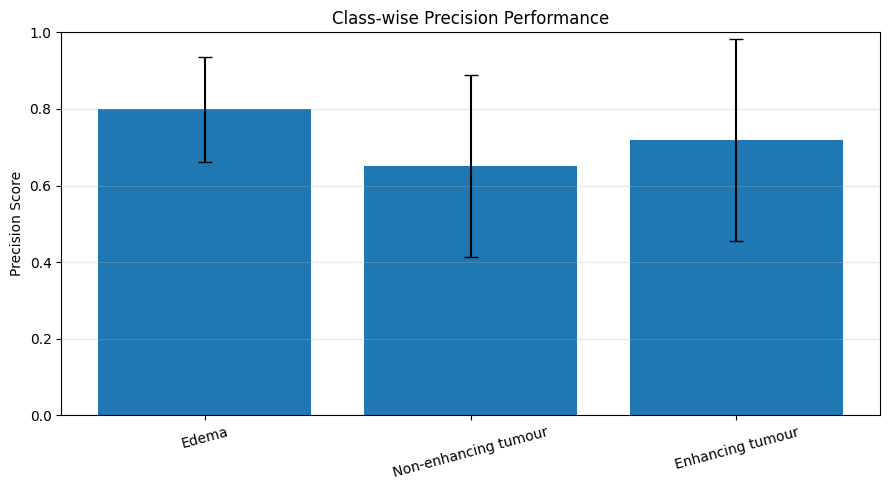

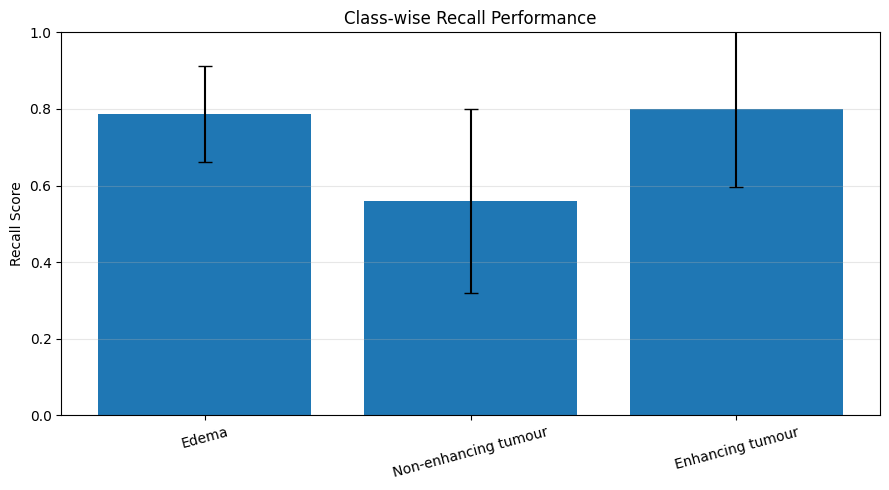

In [92]:
# Phase 4 – Advanced evaluation and performance graphs
# Step 1 – Generate performance graphs
import matplotlib.pyplot as plt
import numpy as np
import os

graph_dir = "/content/drive/MyDrive/BrainTumorProject/evaluation/graphs"
os.makedirs(graph_dir, exist_ok=True)

classes = [
    "Edema",
    "Non-enhancing tumour",
    "Enhancing tumour"
]

metrics = ["Dice", "IoU", "Precision", "Recall"]

for metric in metrics:

    means = [
        df[f"{cls}_{metric}"].mean()
        for cls in classes
    ]

    stds = [
        df[f"{cls}_{metric}"].std()
        for cls in classes
    ]

    plt.figure(figsize=(9, 5))

    plt.bar(classes, means, yerr=stds, capsize=5)

    plt.ylim(0, 1)
    plt.ylabel(metric + " Score")
    plt.title(f"Class-wise {metric} Performance")
    plt.xticks(rotation=15)
    plt.grid(axis="y", alpha=0.3)

    plt.tight_layout()

    plt.savefig(
        os.path.join(graph_dir, f"{metric.lower()}_comparison.png"),
        dpi=300
    )

    plt.show()

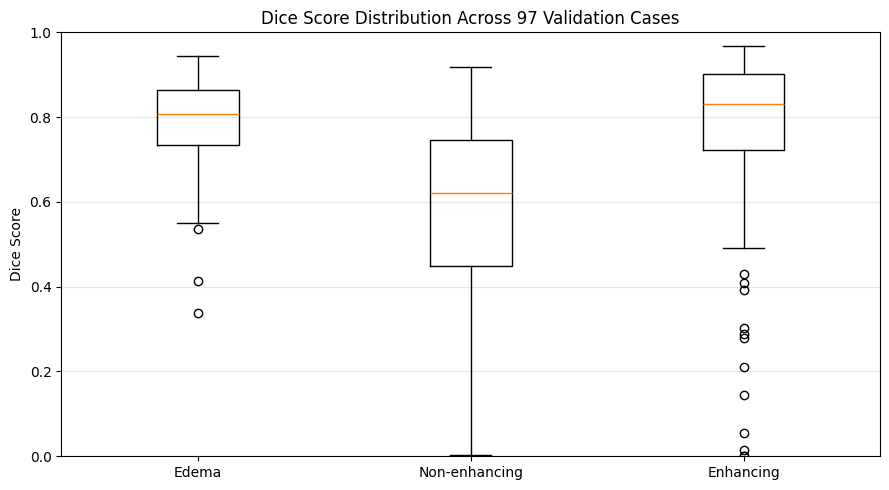

In [93]:
# tep 2 – Generate Dice distribution graph
plt.figure(figsize=(9, 5))

plt.boxplot(
    [
        df["Edema_Dice"],
        df["Non-enhancing tumour_Dice"],
        df["Enhancing tumour_Dice"]
    ],
    tick_labels=[
        "Edema",
        "Non-enhancing",
        "Enhancing"
    ]
)

plt.ylabel("Dice Score")
plt.title("Dice Score Distribution Across 97 Validation Cases")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    os.path.join(graph_dir, "dice_distribution.png"),
    dpi=300
)

plt.show()

In [94]:
# Step 3 – Calculate HD95
# HD95 is a useful additional metric for medical image segmentation because Dice alone does not describe boundary accuracy.
from scipy.ndimage import binary_erosion, distance_transform_edt

def calculate_hd95(pred_mask, gt_mask, spacing=(1, 1, 1)):

    pred_mask = pred_mask.astype(bool)
    gt_mask = gt_mask.astype(bool)

    if not pred_mask.any() and not gt_mask.any():
        return 0.0

    if not pred_mask.any() or not gt_mask.any():
        return np.nan

    pred_surface = pred_mask ^ binary_erosion(pred_mask)
    gt_surface = gt_mask ^ binary_erosion(gt_mask)

    distance_gt = distance_transform_edt(
        ~gt_surface, sampling=spacing
    )

    distance_pred = distance_transform_edt(
        ~pred_surface, sampling=spacing
    )

    distances = np.concatenate([
        distance_gt[pred_surface],
        distance_pred[gt_surface]
    ])

    return np.percentile(distances, 95)

In [95]:
hd95_results = {}

for label, name in class_names.items():

    hd95_results[name] = calculate_hd95(
        prediction == label,
        ground_truth == label,
        spacing=(1, 1, 1)
    )

print("HD95 test:", hd95_results)

HD95 test: {'Edema': np.float64(2.449489742783178), 'Non-enhancing tumour': np.float64(3.1622776601683795), 'Enhancing tumour': np.float64(1.0)}


In [96]:
# Phase 4 – Step 4: HD95 evaluation across all 97 cases
import os
import json
import torch
import numpy as np
import pandas as pd

from monai.transforms import (
    Compose,
    LoadImaged,
    EnsureChannelFirstd,
    NormalizeIntensityd,
    EnsureTyped
)
from monai.inferers import sliding_window_inference
from scipy.ndimage import binary_erosion, distance_transform_edt

def calculate_hd95(pred_mask, gt_mask, spacing=(1, 1, 1)):

    pred_mask = pred_mask.astype(bool)
    gt_mask = gt_mask.astype(bool)

    if not pred_mask.any() and not gt_mask.any():
        return 0.0

    if not pred_mask.any() or not gt_mask.any():
        return np.nan

    pred_surface = pred_mask ^ binary_erosion(pred_mask)
    gt_surface = gt_mask ^ binary_erosion(gt_mask)

    distance_gt = distance_transform_edt(
        ~gt_surface, sampling=spacing
    )

    distance_pred = distance_transform_edt(
        ~pred_surface, sampling=spacing
    )

    distances = np.concatenate([
        distance_gt[pred_surface],
        distance_pred[gt_surface]
    ])

    return float(np.percentile(distances, 95))


# Load validation cases
with open(val_json, "r") as f:
    val_files = json.load(f)

hd95_results = []

model.eval()

for i, item in enumerate(val_files):

    data = val_transform(item)

    image = data["image"].unsqueeze(0).to(device)
    gt = data["label"][0].cpu().numpy().astype(np.uint8)

    with torch.no_grad():
        logits = sliding_window_inference(
            image,
            roi_size=(96, 96, 96),
            sw_batch_size=1,
            predictor=model,
            overlap=0.25
        )

        pred = torch.argmax(logits, dim=1)[0]
        pred = pred.cpu().numpy().astype(np.uint8)

    row = {"Case": os.path.basename(item["image"])}

    for label, name in class_names.items():

        row[f"{name}_HD95"] = calculate_hd95(
            pred == label,
            gt == label,
            spacing=(1, 1, 1)
        )

    hd95_results.append(row)

    print(f"HD95 processed: {i + 1}/{len(val_files)}")


# Create results table
hd95_df = pd.DataFrame(hd95_results)

hd95_summary = hd95_df.drop(columns=["Case"]).agg(
    ["mean", "std"]
).T

print("\nHD95 VALIDATION SUMMARY (mm)")
display(hd95_summary.round(3))

HD95 processed: 1/97
HD95 processed: 2/97
HD95 processed: 3/97
HD95 processed: 4/97
HD95 processed: 5/97
HD95 processed: 6/97
HD95 processed: 7/97
HD95 processed: 8/97
HD95 processed: 9/97
HD95 processed: 10/97
HD95 processed: 11/97
HD95 processed: 12/97
HD95 processed: 13/97
HD95 processed: 14/97
HD95 processed: 15/97
HD95 processed: 16/97
HD95 processed: 17/97
HD95 processed: 18/97
HD95 processed: 19/97
HD95 processed: 20/97
HD95 processed: 21/97
HD95 processed: 22/97
HD95 processed: 23/97
HD95 processed: 24/97
HD95 processed: 25/97
HD95 processed: 26/97
HD95 processed: 27/97
HD95 processed: 28/97
HD95 processed: 29/97
HD95 processed: 30/97
HD95 processed: 31/97
HD95 processed: 32/97
HD95 processed: 33/97
HD95 processed: 34/97
HD95 processed: 35/97
HD95 processed: 36/97
HD95 processed: 37/97
HD95 processed: 38/97
HD95 processed: 39/97
HD95 processed: 40/97
HD95 processed: 41/97
HD95 processed: 42/97
HD95 processed: 43/97
HD95 processed: 44/97
HD95 processed: 45/97
HD95 processed: 46/

,mean,std
Edema_HD95,10.344,17.810
Non-enhancing tumour_HD95,9.214,12.155
Enhancing tumour_HD95,8.826,16.330


In [97]:
# Step 5 – Save HD95 results
hd95_dir = "/content/drive/MyDrive/BrainTumorProject/evaluation"

hd95_df.to_csv(
    os.path.join(hd95_dir, "validation_hd95_casewise.csv"),
    index=False
)

hd95_summary.to_csv(
    os.path.join(hd95_dir, "validation_hd95_summary.csv")
)

print("HD95 evaluation saved successfully.")

HD95 evaluation saved successfully.


In [98]:
print("Valid HD95 cases:")
print(hd95_df.notna().sum())

Valid HD95 cases:
Case                         97
Edema_HD95                   97
Non-enhancing tumour_HD95    97
Enhancing tumour_HD95        95
dtype: int64


In [ ]:
# # Phase 5 – Model Explainability using 3D Grad-CAM
# Step 1 – Understand the approach
# We will:
# 1. Select a validation MRI case.
# 2. Choose a tumour class (edema, non-enhancing, or enhancing).
# 3. Extract activations from the final encoder layer.
# 4. Calculate gradients for the selected class.
# 5. Generate a 3D activation heatmap.
# 6. Overlay the heatmap on the original FLAIR MRI.


In [99]:
print(model)

UNet(
  (model): Sequential(
    (0): ResidualUnit(
      (conv): Sequential(
        (unit0): Convolution(
          (conv): Conv3d(4, 16, kernel_size=(3, 3, 3), stride=(2, 2, 2), padding=(1, 1, 1))
          (adn): ADN(
            (N): InstanceNorm3d(16, eps=1e-05, momentum=0.1, affine=False, bias=False, track_running_stats=False)
            (D): Dropout(p=0.0, inplace=False)
            (A): PReLU(num_parameters=1)
          )
        )
        (unit1): Convolution(
          (conv): Conv3d(16, 16, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1))
          (adn): ADN(
            (N): InstanceNorm3d(16, eps=1e-05, momentum=0.1, affine=False, bias=False, track_running_stats=False)
            (D): Dropout(p=0.0, inplace=False)
            (A): PReLU(num_parameters=1)
          )
        )
      )
      (residual): Conv3d(4, 16, kernel_size=(3, 3, 3), stride=(2, 2, 2), padding=(1, 1, 1))
    )
    (1): SkipConnection(
      (submodule): Sequential(
        (0): ResidualUn

In [100]:
# Step 3 – Inspect available layer names
for name, module in model.named_modules():
    if isinstance(module, torch.nn.Conv3d):
        print(name, module)

model.0.conv.unit0.conv Conv3d(4, 16, kernel_size=(3, 3, 3), stride=(2, 2, 2), padding=(1, 1, 1))
model.0.conv.unit1.conv Conv3d(16, 16, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1))
model.0.residual Conv3d(4, 16, kernel_size=(3, 3, 3), stride=(2, 2, 2), padding=(1, 1, 1))
model.1.submodule.0.conv.unit0.conv Conv3d(16, 32, kernel_size=(3, 3, 3), stride=(2, 2, 2), padding=(1, 1, 1))
model.1.submodule.0.conv.unit1.conv Conv3d(32, 32, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1))
model.1.submodule.0.residual Conv3d(16, 32, kernel_size=(3, 3, 3), stride=(2, 2, 2), padding=(1, 1, 1))
model.1.submodule.1.submodule.0.conv.unit0.conv Conv3d(32, 64, kernel_size=(3, 3, 3), stride=(2, 2, 2), padding=(1, 1, 1))
model.1.submodule.1.submodule.0.conv.unit1.conv Conv3d(64, 64, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1))
model.1.submodule.1.submodule.0.residual Conv3d(32, 64, kernel_size=(3, 3, 3), stride=(2, 2, 2), padding=(1, 1, 1))
model.1.submodule.1.subm

In [101]:
# Phase 5 – 3D Grad-CAM implementation
model.model[1].submodule[1].submodule[1].submodule.conv.unit1.conv

Conv3d(128, 128, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1))

In [102]:
# Step 1 – Select a validation MRI case
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import os

# Select a validation case
case = val_files[0]
data = val_transform(case)

image = data["image"].unsqueeze(0).to(device)

# Get full-volume prediction
model.eval()

with torch.no_grad():
    logits = sliding_window_inference(
        image,
        roi_size=(96, 96, 96),
        sw_batch_size=1,
        predictor=model,
        overlap=0.25
    )

    full_prediction = torch.argmax(logits, dim=1)[0].cpu().numpy()

print("Selected case:", os.path.basename(case["image"]))
print("Prediction shape:", full_prediction.shape)

Selected case: BRATS_419.nii.gz
Prediction shape: (240, 240, 155)


In [103]:
# Step 2 – Select a tumour region and extract a 3D crop
# Select target class
class_counts = {
    c: np.sum(full_prediction == c)
    for c in [1, 2, 3]
}

target_class = max(class_counts, key=class_counts.get)

if class_counts[target_class] == 0:
    raise ValueError("No tumour voxels predicted in this case.")

class_names = {
    1: "Edema",
    2: "Non-enhancing tumour",
    3: "Enhancing tumour"
}

# Find centre of selected tumour region
coords = np.where(full_prediction == target_class)

center = [int(np.mean(axis)) for axis in coords]

# Extract 96 x 96 x 96 crop
roi = 96
starts = [
    max(0, min(c - roi // 2, dim - roi))
    for c, dim in zip(center, full_prediction.shape)
]

x, y, z = starts

image_crop = image[
    :, :,
    x:x+roi,
    y:y+roi,
    z:z+roi
].clone()

print("Target class:", class_names[target_class])
print("Crop shape:", image_crop.shape)

Target class: Edema
Crop shape: torch.Size([1, 4, 96, 96, 96])


In [104]:
# Step 3 – Generate 3D Grad-CAM
# Target final encoder convolution
target_layer = (
    model.model[1]
    .submodule[1]
    .submodule[1]
    .submodule.conv.unit1.conv
)

activations = {}
gradients = {}

def forward_hook(module, input, output):
    activations["value"] = output

def backward_hook(module, grad_input, grad_output):
    gradients["value"] = grad_output[0]

forward_handle = target_layer.register_forward_hook(forward_hook)
backward_handle = target_layer.register_full_backward_hook(backward_hook)

model.zero_grad(set_to_none=True)

input_tensor = image_crop.detach().requires_grad_(True)

# Forward pass with gradients enabled
output = model(input_tensor)
probabilities = torch.softmax(output, dim=1)

# Use predicted voxels of the selected class as the target
predicted_crop = torch.argmax(output, dim=1)[0]
target_mask = predicted_crop == target_class

if not target_mask.any():
    forward_handle.remove()
    backward_handle.remove()
    raise ValueError("Selected tumour class is absent in the crop.")

target_score = probabilities[0, target_class][target_mask].mean()

# Backpropagation
target_score.backward()

# Calculate Grad-CAM
acts = activations["value"]
grads = gradients["value"]

weights = grads.mean(dim=(2, 3, 4), keepdim=True)

cam = torch.relu((weights * acts).sum(dim=1, keepdim=True))

cam = F.interpolate(
    cam,
    size=(roi, roi, roi),
    mode="trilinear",
    align_corners=False
)

cam = cam[0, 0].detach().cpu().numpy()

# Normalize heatmap
cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

# Remove hooks
forward_handle.remove()
backward_handle.remove()

print("Grad-CAM shape:", cam.shape)
print("Grad-CAM range:", cam.min(), cam.max())

Grad-CAM shape: (96, 96, 96)
Grad-CAM range: 0.0 5.8679838e-05


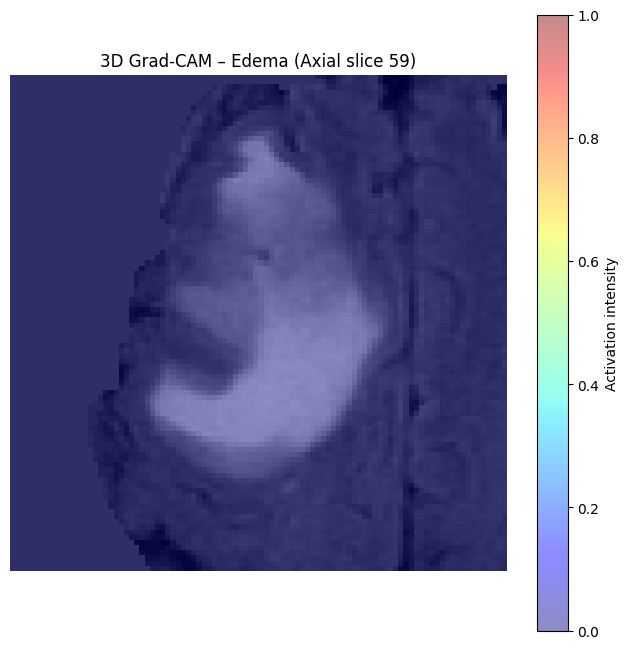

In [105]:
# Step 4 – Visualize the Grad-CAM heatmap
# Select axial slice with maximum Grad-CAM activation
slice_idx = int(np.argmax(cam.sum(axis=(0, 1))))

flair_crop = image_crop[0, 0].detach().cpu().numpy()

plt.figure(figsize=(8, 8))

plt.imshow(
    flair_crop[:, :, slice_idx].T,
    cmap="gray",
    origin="lower"
)

plt.imshow(
    cam[:, :, slice_idx].T,
    cmap="jet",
    alpha=0.45,
    origin="lower",
    vmin=0,
    vmax=1
)

plt.title(
    f"3D Grad-CAM – {class_names[target_class]} "
    f"(Axial slice {slice_idx})"
)

plt.axis("off")
plt.colorbar(label="Activation intensity")
plt.show()

In [106]:
# Step 5 – Save the Grad-CAM result
gradcam_dir = (
    "/content/drive/MyDrive/BrainTumorProject/visualizations/GradCAM"
)

os.makedirs(gradcam_dir, exist_ok=True)

plt.figure(figsize=(8, 8))

plt.imshow(flair_crop[:, :, slice_idx].T, cmap="gray", origin="lower")
plt.imshow(
    cam[:, :, slice_idx].T,
    cmap="jet",
    alpha=0.45,
    origin="lower",
    vmin=0,
    vmax=1
)

plt.axis("off")
plt.title(f"Grad-CAM - {class_names[target_class]}")

plt.savefig(
    os.path.join(gradcam_dir, "gradcam_test.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.close()

print("Grad-CAM visualization saved.")

Grad-CAM visualization saved.


In [108]:
# Phase 5 – Step 6: Generate Grad-CAM for all three tumour classes
# Step 1 – Create a reusable Grad-CAM function
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import os

target_layer = (
    model.model[1]
    .submodule[1]
    .submodule[1]
    .submodule.conv.unit1.conv
)

def generate_gradcam(image, full_prediction, target_class, roi=96):

    coords = np.where(full_prediction == target_class)

    if len(coords[0]) == 0:
        print(f"Class {target_class} absent. Skipping.")
        return None

    center = [int(np.mean(axis)) for axis in coords]

    starts = [
        max(0, min(c - roi // 2, dim - roi))
        for c, dim in zip(center, full_prediction.shape)
    ]

    x, y, z = starts

    image_crop = image[
        :, :,
        x:x+roi,
        y:y+roi,
        z:z+roi
    ].detach().clone().requires_grad_(True)

    activations = {}
    gradients = {}

    def forward_hook(module, inputs, output):
        activations["value"] = output

    def backward_hook(module, grad_input, grad_output):
        gradients["value"] = grad_output[0]

    h1 = target_layer.register_forward_hook(forward_hook)
    h2 = target_layer.register_full_backward_hook(backward_hook)

    try:
        model.zero_grad(set_to_none=True)

        output = model(image_crop)
        probabilities = torch.softmax(output, dim=1)

        pred_crop = torch.argmax(output, dim=1)[0]
        target_mask = pred_crop == target_class

        if not target_mask.any():
            return None

        score = probabilities[0, target_class][target_mask].mean()
        score.backward()

        acts = activations["value"]
        grads = gradients["value"]

        weights = grads.mean(
            dim=(2, 3, 4),
            keepdim=True
        )

        cam = torch.relu(
            (weights * acts).sum(dim=1, keepdim=True)
        )

        cam = F.interpolate(
            cam,
            size=(roi, roi, roi),
            mode="trilinear",
            align_corners=False
        )

        cam = cam[0, 0].detach().cpu().numpy()

        cam = (
            (cam - cam.min()) /
            (cam.max() - cam.min() + 1e-8)
        )

        return {
            "cam": cam,
            "flair": image_crop[0, 0].detach().cpu().numpy(),
            "start": starts
        }

    finally:
        h1.remove()
        h2.remove()

Generating Grad-CAM: Edema


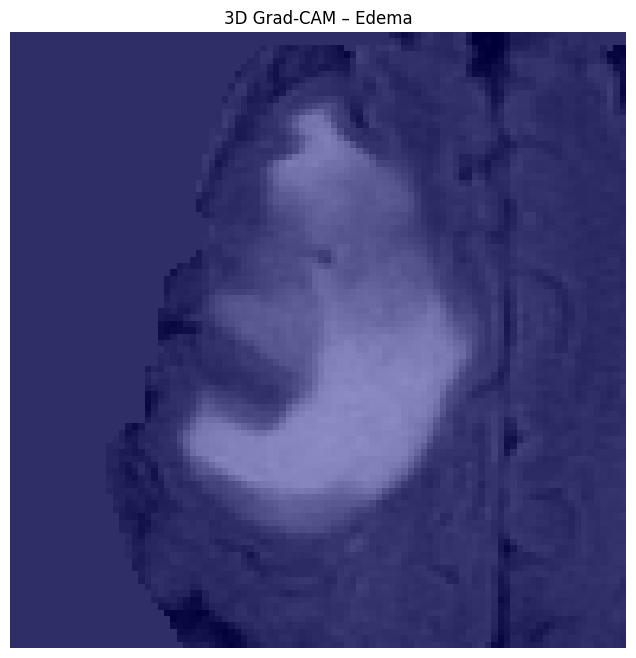

Generating Grad-CAM: Non-enhancing tumour


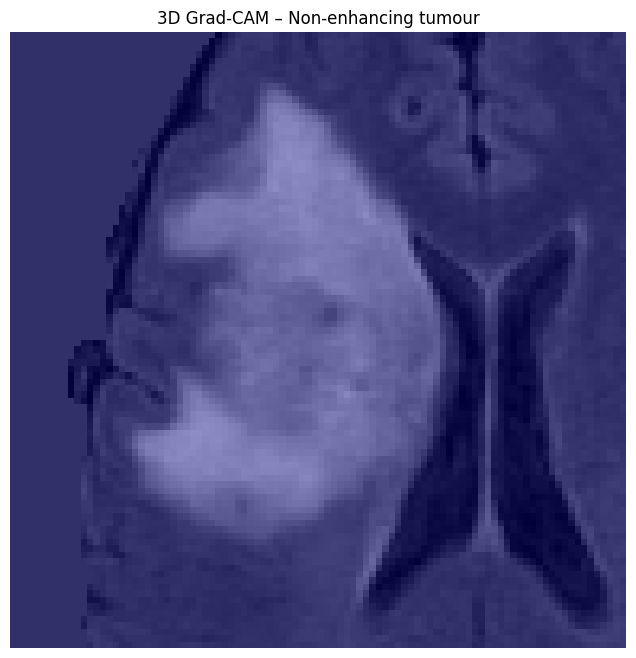

Generating Grad-CAM: Enhancing tumour


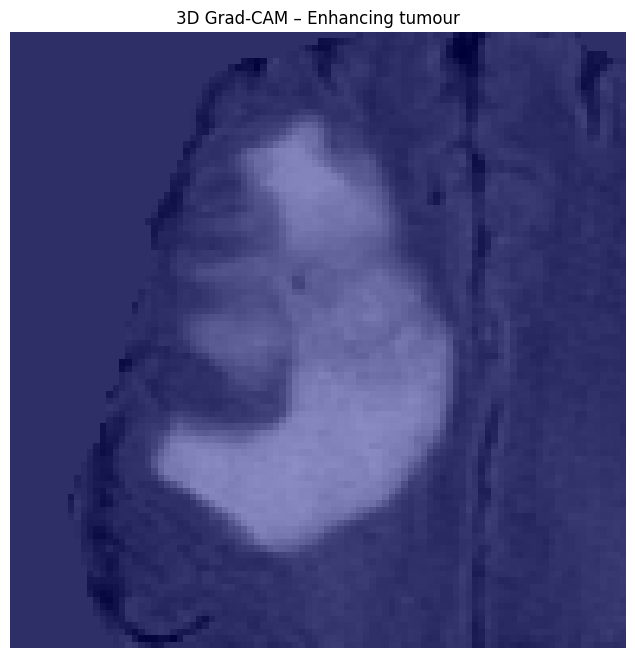

All available class Grad-CAM maps generated.


In [109]:
# Step 2 – Generate and save all class heatmaps
class_names = {
    1: "Edema",
    2: "Non-enhancing tumour",
    3: "Enhancing tumour"
}

gradcam_dir = (
    "/content/drive/MyDrive/BrainTumorProject/"
    "visualizations/GradCAM"
)

os.makedirs(gradcam_dir, exist_ok=True)

gradcam_results = {}

for label, name in class_names.items():

    print("Generating Grad-CAM:", name)

    result = generate_gradcam(
        image,
        full_prediction,
        target_class=label
    )

    if result is None:
        continue

    gradcam_results[label] = result

    cam = result["cam"]
    flair_crop = result["flair"]

    slice_idx = int(np.argmax(cam.sum(axis=(0, 1))))

    plt.figure(figsize=(8, 8))

    plt.imshow(
        flair_crop[:, :, slice_idx].T,
        cmap="gray",
        origin="lower"
    )

    plt.imshow(
        cam[:, :, slice_idx].T,
        cmap="jet",
        alpha=0.45,
        origin="lower",
        vmin=0,
        vmax=1
    )

    plt.title(f"3D Grad-CAM – {name}")
    plt.axis("off")

    plt.savefig(
        os.path.join(
            gradcam_dir,
            f"gradcam_class_{label}.png"
        ),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

print("All available class Grad-CAM maps generated.")

In [110]:
# Step 3 – Check generated files
print("Generated Grad-CAM files:")

for file in sorted(os.listdir(gradcam_dir)):
    print(file)

Generated Grad-CAM files:
gradcam_class_1.png
gradcam_class_2.png
gradcam_class_3.png
gradcam_test.png
